# PASO 5: Modelos No Supervisados - Segmentación de perfiles profesionales

**Objetivo:** Descubrir, sin usar el salario como guía, qué **perfiles de trayectoria profesional** existen entre las personas que respondieron la encuesta de remuneración IT en Argentina, y recién después ver cómo se comportan esos grupos en salario, seniority, contrato y modalidad.

**Algoritmos que se aplican y comparan:** K-Means, DBSCAN y Clustering Jerárquico (aglomerativo). Además se usa **PCA/SVD** para visualizar los grupos en un plano.

**Stack:** `sys`, `os`, `warnings`, `pandas`, `numpy`, `matplotlib`, `seaborn`, `scipy` (`linkage`, `dendrogram`, `fcluster`), `scikit-learn` (`StandardScaler`, `KMeans`, `DBSCAN`, `PCA`, `TruncatedSVD`, `silhouette_score`, `adjusted_rand_score`)

> Al terminar exportamos `dataset_clusters.csv` con el segmento asignado a cada persona.

### Contexto y consigna

En los pasos 03 y 04 siempre hubo una variable objetivo: predecimos el `salario` (regresión) y si el sueldo estaba dolarizado (clasificación). Acá cambiamos de enfoque: **no hay etiqueta que predecir**. El algoritmo tiene que encontrar por sí solo la estructura de los datos.

> **Consigna:** Aprendizaje no supervisado: desarrollar un modelo de clustering desde el AED hasta su mejora. Elegir un algoritmo y aplicarlo al proyecto, con una revisión y decisiones tomadas bajo un criterio que deben explicitar.

**Pregunta de negocio:** ¿Existen grupos naturales de profesionales según su recorrido (experiencia, antigüedad, tiempo en el puesto y edad)? Y si existen, ¿se diferencian en lo que cobran?

**Cómo documentamos las decisiones.** Cada decisión importante sigue el mismo esquema, para que el criterio quede explícito:

1. **Pregunta:** qué hay que decidir.
2. **Evidencia:** qué mostramos para decidir (gráfico o tabla).
3. **Criterio:** la regla que usamos para elegir.
4. **Decisión:** qué elegimos, y qué alternativa quedó descartada.

Al final de cada bloque de código hay una **conclusión en palabras simples**, pensada para que se entienda qué se quiso comprobar aunque no se conozca la técnica. Al final del notebook hay un **registro de decisiones** que junta todo.

### Índice de partes

* **Parte 0:** Preparación del entorno y carga de datos
* **Parte 1:** ¿Con qué dataset trabajamos y por qué?
* **Parte 2:** Análisis exploratorio orientado a clustering (AED)
* **Parte 3:** Escalado de variables
* **Parte 4:** Elección de los algoritmos
* **Parte 5:** K-Means: modelo base, revisión y mejora
* **Parte 6:** DBSCAN
* **Parte 7:** Clustering jerárquico
* **Parte 8:** Comparación de modelos y decisión final
* **Parte 9:** Visualización y reducción de dimensiones: PCA y SVD
* **Parte 10:** Interpretación de los segmentos del modelo final
* **Parte 11:** Conclusiones, registro de decisiones y exportación

## Parte 0: Preparación del entorno y carga de datos

In [1]:
import sys
import os

# Agrega la carpeta raíz del proyecto al path de Python
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..')))

# Importa la función desde helpers.py
from helpers import formato_moneda

In [2]:
# Remueve cualquier tipo de advertencia de FutureWarning
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

# Carga de librerías esenciales
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

# Preparación, clustering y reducción de dimensionalidad
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.neighbors import NearestNeighbors
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

# Métricas de evaluación
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

# Carga del dataset limpio (salida del notebook 01)
df = pd.read_csv('../data/dataset_clean.csv')

print(f"Dimensiones del dataset: {df.shape[0]} filas y {df.shape[1]} columnas.")
display(df.head(3))

Dimensiones del dataset: 4387 filas y 26 columnas.


,donde_estas_trabajando,dedicacion,tipo_de_contrato,modalidad_de_trabajo,sueldo_dolarizado,contas_con_beneficios_adicionales,estas_buscando_trabajo,tenes_guardias,trabajo_de,seniority,...,bases_de_datos,qa_testing,cantidad_de_personas_en_tu_organizacion,maximo_nivel_de_estudios,estado,carrera,tengo_edad,genero,salario,es_jerarquico
0,Mendoza,Full-Time,Staff (Planta Permanente),Híbrido (Presencial Y Remoto),True,"Capacitaciones Y/O Cursos, Descuento En Gimnas...","No, Pero Escucho Ofertas.",NaN,Developer,Senior,...,"Amazon Dynamodb, Elasticsearch, Google Cloud S...","Junit, Selenium",De 1001 A 2000 Personas,NaN,NaN,NaN,45,Mujer Cis,3000000.0,False
1,Santa Fe,Full-Time,Contractor,100% Remoto,True,Ninguna De Las Anteriores,"No, Estoy Muy Conforme.",NaN,Developer,Senior,...,Microsoft Sql Server,Postman,De 51 A 100 Personas,NaN,NaN,NaN,50,Mujer Cis,5000000.0,False
2,Buenos Aires,Full-Time,Tercerizado (Trabajo A Través De Consultora O ...,100% Remoto,True,"Abono De Internet, Clases De Idiomas, Crédito ...","No, Pero Escucho Ofertas.",No,Developer,Senior,...,Amazon Rds/Aurora,Postman,De 51 A 100 Personas,Universitario,Completo,Ingeniería En Sistemas De Información,36,Mujer Cis,4600000.0,False


## Parte 1: ¿Con qué dataset trabajamos y por qué?

**Pregunta:** tenemos dos archivos disponibles, `dataset_clean.csv` (salida del 01) y `dataset_features.csv` (salida del 02). ¿Cuál usamos para agrupar?

**Evidencia y criterio:** los tres algoritmos que vamos a usar se basan en **distancias** (qué tan parecidas son dos personas), así que importa mucho qué columnas entran y en qué escala. Además, la consigna pide **interpretar** los grupos, y para eso necesitamos las variables en sus **unidades originales**.

| | `dataset_clean.csv` | `dataset_features.csv` |
|---|---|---|
| Unidades originales (años, pesos) | Sí | No (numéricas ya estandarizadas) |
| Categorías legibles (`seniority`, `tipo_de_contrato`...) | Sí | No (convertidas a columnas 0/1) |
| Cantidad de columnas | Pocas | Muchas columnas binarias (ver notebook 02) |
| Pensado para | Explorar e interpretar | Predecir el salario |

Con tantas columnas binarias, las distancias quedarían dominadas por columnas 0/1 y se diluiría la información de trayectoria.

## Parte 2: Análisis exploratorio orientado a clustering (AED)

En el notebook 01 hicimos un AED general del dataset. Acá repetimos solo lo que condiciona un clustering: qué variables usar, si tienen faltantes o valores raros, qué forma tienen sus distribuciones y si hay variables redundantes.

### 2.1 Selección de variables

**Pregunta:** ¿qué variables usamos para agrupar y cuáles dejamos para interpretar?

**Criterio:** se agrupa con las variables que describen **lo que queremos segmentar** (la trayectoria profesional) y las demás se reservan para **entender y validar** los grupos después.

| Variable | Rol | Por qué |
|---|---|---|
| `anos_de_experiencia` | **Agrupa** | Describe la trayectoria profesional |
| `antiguedad_en_la_empresa_actual` | **Agrupa** | Describe estabilidad en la empresa |
| `anos_en_el_puesto_actual` | **Agrupa** | Describe movilidad dentro de la empresa |
| `tengo_edad` | **Agrupa (a revisar)** | Se solapa con la experiencia. Se evalúa en la Parte 5 |
| `salario` | Interpreta | Si agrupáramos por salario, los clusters serían "rangos de sueldo" y no perfiles. Queremos ver si la trayectoria se relaciona con él |
| `seniority` | Interpreta y valida | Es una etiqueta que la persona declara. Sirve como contraste externo |
| `es_jerarquico`, `sueldo_dolarizado`, `tipo_de_contrato`, `modalidad_de_trabajo`, `trabajo_de`, `genero` | Interpreta | Son categóricas o binarias: no se usan para agrupar (ver Parte 1) |
| Columnas multirrespuesta (tecnologías, bases de datos, beneficios) | Fuera | Generan muchas columnas 0/1 que no se pueden agrupar con distancias |



> **Decisión:** agrupamos con 4 variables numéricas de trayectoria. Las demás se usan solo después, para describir y validar.

In [3]:
# Variables que usamos para agrupar
vars_cluster = [
    "anos_de_experiencia",
    "antiguedad_en_la_empresa_actual",
    "anos_en_el_puesto_actual",
    "tengo_edad",
]

# Variables que usamos solo para interpretar los grupos
vars_interp_cat = ["seniority", "tipo_de_contrato", "modalidad_de_trabajo", "trabajo_de", "genero"]
vars_interp_bin = ["es_jerarquico", "sueldo_dolarizado"]

# Verificamos que existan todas
todas = vars_cluster + ["salario"] + vars_interp_cat + vars_interp_bin
faltantes = [c for c in todas if c not in df.columns]
if faltantes:
    raise ValueError(f"Columnas faltantes en el dataset: {faltantes}")

# Las binarias pueden leerse como bool o como texto según cómo se exportó el CSV: las dejamos como bool
for c in vars_interp_bin:
    df[c] = df[c].astype(str).str.lower().eq("true")

print("Para agrupar:", vars_cluster)
print("Para interpretar (numérica): ['salario']")
print("Para interpretar (categóricas):", vars_interp_cat)
print("Para interpretar (binarias):", vars_interp_bin)

Para agrupar: ['anos_de_experiencia', 'antiguedad_en_la_empresa_actual', 'anos_en_el_puesto_actual', 'tengo_edad']
Para interpretar (numérica): ['salario']
Para interpretar (categóricas): ['seniority', 'tipo_de_contrato', 'modalidad_de_trabajo', 'trabajo_de', 'genero']
Para interpretar (binarias): ['es_jerarquico', 'sueldo_dolarizado']


> **Conclusión** De las 26 columnas, solo 4 se usan para armar los grupos: experiencia, antigüedad en la empresa, años en el puesto y edad. El salario queda afuera a propósito: queremos ver si la trayectoria sola separa grupos y, después, comprobar si esos grupos cobran distinto.

### 2.2 Valores faltantes, valores extremos y coherencia

**Pregunta:** ¿hay datos que puedan distorsionar los clusters?

**Por qué importa:** K-Means calcula el centro de cada grupo como un promedio, por lo que los valores extremos lo desplazan. Y DBSCAN trata como ruido los puntos aislados.

**Criterio:**
* **Faltantes:** nos quedamos solo con las filas completas en las variables para agrupar. Imputar con la mediana crearía muchas personas idénticas "en el medio".
* **Extremos:** en el notebook 01 ya filtramos edades imposibles y salarios extremos. Revisamos si quedan trayectorias extremas con IQR, pero **no las eliminamos** salvo que sean imposibles: una persona con 35 años de experiencia es un perfil real y justamente puede ser un segmento.
* **Coherencia:** la antigüedad en la empresa no debería superar a la experiencia total, ni los años en el puesto a la antigüedad. Si hay pocos casos (menos del 5%) los conservamos sin más. Si hay muchos, también los conservamos, porque eliminar tantas filas sesgaría la muestra, pero lo dejamos documentado como limitación.

In [4]:
# 1. Faltantes en las variables para agrupar
print("Valores faltantes en las variables para agrupar:")
display(df[vars_cluster].isna().sum().to_frame("faltantes"))

# 2. Nos quedamos con las filas completas
antes = len(df)
df_cl = df.dropna(subset=vars_cluster).reset_index(drop=True)
print(f"Filas antes: {antes} | Filas después: {len(df_cl)} | Eliminadas por faltantes: {antes - len(df_cl)}")

# 3. Estadísticos y percentiles
print("\nEstadísticos de las variables para agrupar:")
display(df_cl[vars_cluster].describe().T.round(2))

# 4. Valores extremos por IQR (solo para informar, no se eliminan)
filas = []
for col in vars_cluster:
    q1, q3 = df_cl[col].quantile([0.25, 0.75])
    lim_sup = q3 + 1.5 * (q3 - q1)
    filas.append({
        "variable": col,
        "límite superior (IQR)": round(lim_sup, 1),
        "máximo observado": df_cl[col].max(),
        "casos sobre el límite": int((df_cl[col] > lim_sup).sum()),
        "% sobre el límite": round((df_cl[col] > lim_sup).mean() * 100, 1),
    })
print("\nValores extremos por IQR:")
display(pd.DataFrame(filas))

# 5. Coherencia entre variables de trayectoria
incoh_empresa = (df_cl["antiguedad_en_la_empresa_actual"] > df_cl["anos_de_experiencia"]).mean() * 100
incoh_puesto = (df_cl["anos_en_el_puesto_actual"] > df_cl["antiguedad_en_la_empresa_actual"]).mean() * 100
print(f"\nAntigüedad en la empresa mayor que la experiencia total: {incoh_empresa:.1f}% de las filas")
print(f"Años en el puesto mayores que la antigüedad en la empresa: {incoh_puesto:.1f}% de las filas")

if max(incoh_empresa, incoh_puesto) < 5:
    print("Decisión: porcentaje bajo (< 5%), compatible con redondeos de la encuesta. Se conservan las filas.")
else:
    print("Decisión: porcentaje alto (>= 5%). Son datos autorreportados y cada pregunta se responde por separado. "
          "Eliminar tantas filas sesgaría la muestra, así que se conservan y queda documentado como limitación (Parte 11.3).")

Valores faltantes en las variables para agrupar:


,faltantes
anos_de_experiencia,0
antiguedad_en_la_empresa_actual,0
anos_en_el_puesto_actual,0
tengo_edad,0


Filas antes: 4387 | Filas después: 4387 | Eliminadas por faltantes: 0

Estadísticos de las variables para agrupar:


,count,mean,std,min,25%,50%,75%,max
anos_de_experiencia,4387.0,10.03,8.11,0.0,4.0,7.0,15.0,48.0
antiguedad_en_la_empresa_actual,4387.0,4.52,5.27,0.0,1.0,3.0,5.0,42.0
anos_en_el_puesto_actual,4387.0,3.59,3.84,0.0,1.0,3.0,5.0,40.0
tengo_edad,4387.0,37.10,8.83,16.0,30.0,36.0,43.0,75.0



Valores extremos por IQR:


,variable,límite superior (IQR),máximo observado,casos sobre el límite,% sobre el límite
0,anos_de_experiencia,31.5,48,74,1.7
1,antiguedad_en_la_empresa_actual,11.0,42,430,9.8
2,anos_en_el_puesto_actual,11.0,40,187,4.3
3,tengo_edad,62.5,75,29,0.7



Antigüedad en la empresa mayor que la experiencia total: 6.2% de las filas
Años en el puesto mayores que la antigüedad en la empresa: 14.8% de las filas
Decisión: porcentaje alto (>= 5%). Son datos autorreportados y cada pregunta se responde por separado. Eliminar tantas filas sesgaría la muestra, así que se conservan y queda documentado como limitación (Parte 11.3).


> **Conclusión** Las 4 variables no tienen datos vacíos, así que no se perdió ninguna fila (siguen las 4.387 personas). Hay trayectorias muy largas (hasta 48 años de experiencia), pero son casos reales y se conservan. Un detalle a tener presente: en 6,2% de las personas la antigüedad en la empresa supera a la experiencia total y en 14,8% los años en el puesto superan a la antigüedad. Es una inconsistencia esperable en una encuesta donde cada uno responde por su cuenta, y queda anotada como limitación.

### 2.3 Distribución de cada variable

**Pregunta:** ¿alguna variable tiene cola larga? Con colas largas, unos pocos valores altos tiran de los centros de los grupos, y conviene aplicar una transformación logarítmica.

**Criterio:** usamos la **asimetría (skewness)**. Si es mayor a 1 en valor absoluto, la variable se considera muy asimétrica y queda como candidata a transformación `log1p` (que funciona con ceros). Es una regla de referencia, y la decisión se valida en la Parte 5 comparando con y sin transformación.

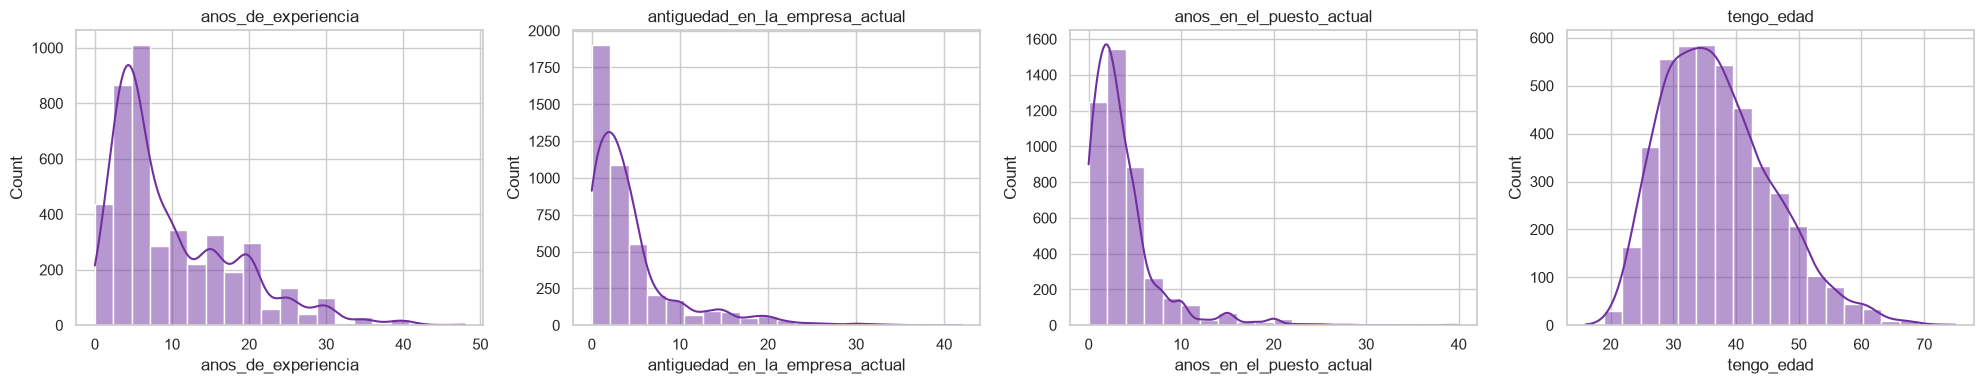

,asimetría (skewness)
anos_de_experiencia,1.27
antiguedad_en_la_empresa_actual,2.35
anos_en_el_puesto_actual,2.92
tengo_edad,0.65


Candidatas a log1p (|asimetría| > 1): ['anos_de_experiencia', 'antiguedad_en_la_empresa_actual', 'anos_en_el_puesto_actual']


In [5]:
# Histogramas de las variables para agrupar
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, col in zip(axes, vars_cluster):
    sns.histplot(df_cl[col], bins=20, kde=True, ax=ax, color="#7030A0")
    ax.set_title(col)
plt.tight_layout()
plt.show()

# Asimetría de cada variable
asimetria = df_cl[vars_cluster].skew().round(2)
display(asimetria.to_frame("asimetría (skewness)"))

# Variables candidatas a transformación logarítmica
vars_sesgadas = [c for c in vars_cluster if abs(asimetria[c]) > 1 and df_cl[c].min() >= 0]
print("Candidatas a log1p (|asimetría| > 1):", vars_sesgadas if vars_sesgadas else "ninguna")

> **Conclusión** La mayoría de las personas tiene pocos años de experiencia, de antigüedad y de tiempo en el puesto, y unas pocas tienen muchos (la cola larga hacia la derecha). Tres de las cuatro variables superan el umbral de asimetría (1), por eso más adelante se prueba aplicarles logaritmo. La edad es la única con una forma bastante simétrica.

### 2.4 Relación entre variables

**Pregunta:** ¿hay variables que dicen casi lo mismo? Si dos variables son casi copias, usar ambas es contar dos veces la misma información.

**Criterio:** miramos las correlaciones entre las 4 variables. Incluimos `salario` en el mapa solo como referencia (no se usa para agrupar). Una variable solo se descarta por redundancia si es casi una copia de otra (correlación cercana a 0,9 o más).

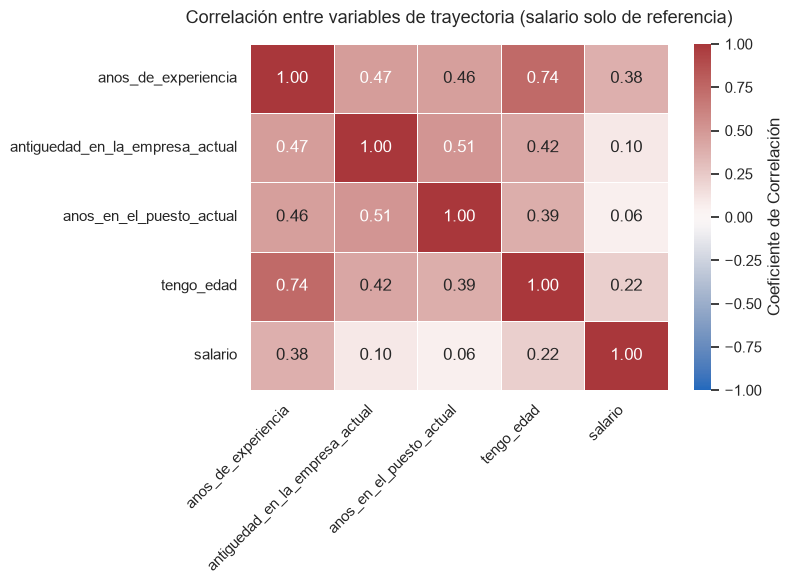

Correlación entre pares de variables para agrupar:
anos_de_experiencia              tengo_edad                         0.74
antiguedad_en_la_empresa_actual  anos_en_el_puesto_actual           0.51
anos_de_experiencia              antiguedad_en_la_empresa_actual    0.47
                                 anos_en_el_puesto_actual           0.46
antiguedad_en_la_empresa_actual  tengo_edad                         0.42
anos_en_el_puesto_actual         tengo_edad                         0.39


In [6]:
# Mapa de calor: variables para agrupar + salario (solo referencia)
corr = df_cl[vars_cluster + ["salario"]].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="vlag", vmin=-1, vmax=1, fmt=".2f", linewidths=0.5,
            cbar_kws={"label": "Coeficiente de Correlación"})
plt.title("Correlación entre variables de trayectoria (salario solo de referencia)", fontsize=13, pad=15)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Pares de variables para agrupar, ordenados de mayor a menor correlación
corr_cluster = df_cl[vars_cluster].corr()
pares = corr_cluster.where(np.triu(np.ones(corr_cluster.shape), k=1).astype(bool)).stack().dropna().sort_values(ascending=False)
print("Correlación entre pares de variables para agrupar:")
print(pares.round(2).to_string())

> **Conclusión** Las variables se mueven juntas, pero ninguna es una copia de otra. La relación más fuerte es experiencia con edad (0,74), lógico porque quien trabaja hace más años suele tener más edad. Como no llega a ser redundancia total, se mantienen las cuatro y la edad se revisa en la Parte 5. El salario, por separado, se relaciona poco con cada variable (0,38 con la experiencia, 0,22 con la edad, 0,10 con la antigüedad y 0,06 con los años en el puesto).

## Parte 3: Escalado de variables

**Pregunta:** ¿hace falta escalar?

**Criterio:** sí. Las cuatro variables están en años, pero con rangos distintos (la experiencia llega a más años que el tiempo en el puesto, por ejemplo), y las distancias darían más peso a las que tienen valores más grandes. Usamos `StandardScaler` (media 0 y desvío 1), igual que en el notebook 02.

> **Decisión:** escalamos con `StandardScaler`. Esta es la **versión 1 (base)** de los datos. En la Parte 5 la comparamos con otras versiones.

In [7]:
# Versión base: las 4 variables, sin transformar, escaladas
X_base = StandardScaler().fit_transform(df_cl[vars_cluster])

print("Forma de la matriz (personas x variables):", X_base.shape)
display(pd.DataFrame(X_base, columns=vars_cluster).describe().loc[["mean", "std"]].round(2))

Forma de la matriz (personas x variables): (4387, 4)


,anos_de_experiencia,antiguedad_en_la_empresa_actual,anos_en_el_puesto_actual,tengo_edad
mean,-0.0,0.0,0.0,0.0
std,1.0,1.0,1.0,1.0


> **Conclusión** Las 4 variables quedaron en la misma escala (promedio 0 y desvío 1). Así ninguna pesa más que otra cuando el algoritmo mide qué tan parecidas son dos personas.

## Parte 4: Elección de los algoritmos

**Pregunta:** ¿qué algoritmos de clustering aplicamos y cuál desarrollamos como modelo principal?

**Evidencia:** comparamos los tres contra las características de este dataset.

| Aspecto | K-Means | DBSCAN | Jerárquico (aglomerativo) |
|---|---|---|---|
| Idea de "grupo" | Alrededor de un centro (el perfil promedio) | Zona densa de personas parecidas, separada de otras por zonas vacías | Grupos que se van uniendo de a pares, de abajo hacia arriba |
| Cantidad de clusters | Se fija (`k`) | Se descubre | Se decide mirando el árbol (dendrograma) |
| Parámetros | `k` | `eps` y `min_samples` (muy sensibles) | Tipo de enlace y punto de corte |
| Valores extremos | Los asigna a un grupo y desplazan centros | Los marca como ruido (etiqueta -1) | Según el enlace, pueden formar grupos de una sola persona |
| ¿Todas las personas quedan en un grupo? | Sí | No (el ruido queda afuera) | Sí |
| Hipótesis para nuestros datos | Es una encuesta: la trayectoria probablemente sea un continuo, y K-Means lo parte en tramos | Si no hay "islas" separadas, DBSCAN tendrá dificultades | Sirve para ver la estructura a distintos niveles de detalle |

**Criterio:** el modelo principal es el que mejor responde a la pregunta de negocio: segmentar a **toda la muestra** en **pocos perfiles interpretables**. Los otros dos se aplican igual y se contrastan con una regla fija que definimos antes de ver los resultados (Parte 8).

> **Decisión:** **K-Means** es el modelo principal (Parte 5). **DBSCAN** (Parte 6) y el **jerárquico** (Parte 7) se aplican sobre la misma matriz de datos y compiten con K-Means en la Parte 8. Solo lo reemplazan si cumplen el criterio y lo superan.

## Parte 5: K-Means: modelo base, revisión y mejora

### 5.1 Elección de k

**Pregunta:** ¿cuántos segmentos pedimos?

**Evidencia:** para k de 2 a 10 calculamos tres cosas: la **inercia** (método del codo: cuánto se "aprietan" los grupos al agregar más), el **coeficiente de Silhouette** (qué tan bien separada está cada persona de los otros grupos) y el **tamaño del cluster más chico**.

**Criterio:** con datos reales suele no haber un codo marcado, y el Silhouette tiende a favorecer k = 2. Entonces combinamos:
* k entre **3 y 6**: pocos segmentos para que la empresa pueda actuar distinto con cada uno.
* Ningún cluster con menos del **5%** de las personas: evitamos segmentos irrelevantes.
* Entre los k que cumplen, elegimos el de **mayor Silhouette**.

Si ningún k cumple, se elige el de mayor Silhouette sin restricciones.

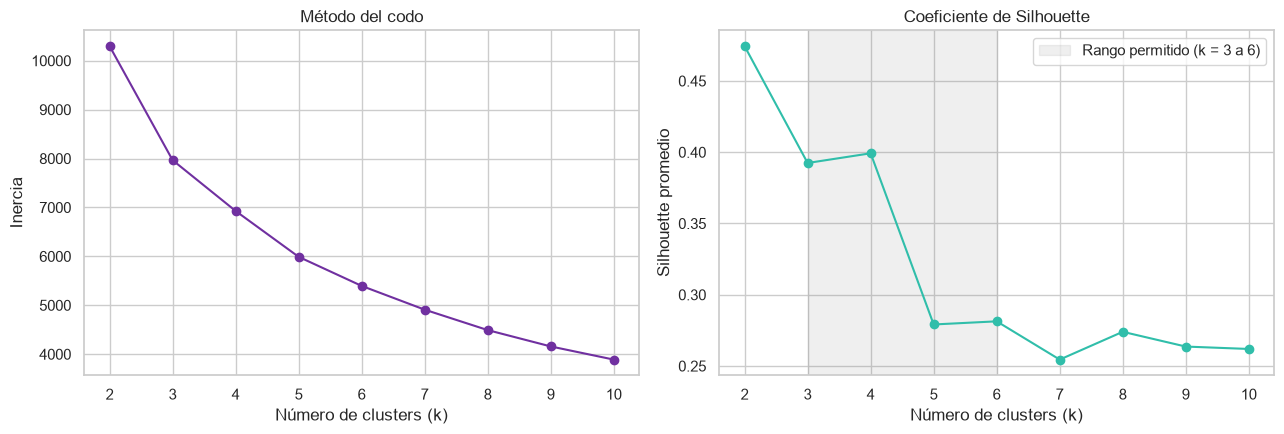

,k,inercia,silhouette,cluster_mas_chico_%
0,2,10297.535,0.474,25.370
1,3,7965.825,0.392,8.160
2,4,6927.309,0.399,4.718
3,5,5989.668,0.279,4.057
4,6,5395.186,0.281,3.488
5,7,4909.577,0.254,3.168
6,8,4491.939,0.274,1.596
7,9,4158.002,0.264,2.348
8,10,3889.015,0.262,1.276


Decisión (versión base): k = 3


In [ ]:
# Reglas para elegir k (se explican en el texto de arriba)
K_MIN, K_MAX = 3, 6
MIN_PCT_CLUSTER = 5.0

def evaluar_k(X, valores_k=range(2, 11)):
    # Entrena K-Means para cada k y devuelve inercia, Silhouette y tamaño del cluster más chico
    filas = []
    for k in valores_k:
        km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
        tamanos = np.bincount(km.labels_) / len(X) * 100
        filas.append({
            "k": k,
            "inercia": km.inertia_,
            "silhouette": silhouette_score(X, km.labels_),
            "cluster_mas_chico_%": tamanos.min(),
        })
    return pd.DataFrame(filas)


def elegir_k(tabla):
    # Aplica el criterio: k entre K_MIN y K_MAX, clusters >= MIN_PCT_CLUSTER, mayor Silhouette
    validos = tabla[tabla["k"].between(K_MIN, K_MAX) & (tabla["cluster_mas_chico_%"] >= MIN_PCT_CLUSTER)]
    if validos.empty:
        validos = tabla
    return int(validos.loc[validos["silhouette"].idxmax(), "k"])


tabla_base = evaluar_k(X_base)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(tabla_base["k"], tabla_base["inercia"], "o-", color="#7030A0")
ax[0].set_title("Método del codo")
ax[0].set_xlabel("Número de clusters (k)")
ax[0].set_ylabel("Inercia")

ax[1].plot(tabla_base["k"], tabla_base["silhouette"], "o-", color="#30BEAA")
ax[1].axvspan(K_MIN, K_MAX, color="gray", alpha=0.12, label=f"Rango permitido (k = {K_MIN} a {K_MAX})")
ax[1].set_title("Coeficiente de Silhouette")
ax[1].set_xlabel("Número de clusters (k)")
ax[1].set_ylabel("Silhouette promedio")
ax[1].legend()
plt.tight_layout()
plt.show()

display(tabla_base.round(3))

k_base = elegir_k(tabla_base)
print(f"Decisión (versión base): k = {k_base}")

> **Conclusión** No hay un codo claro: la inercia baja de forma gradual. El Silhouette más alto es el de k = 2 (0,47), pero dos grupos son pocos para segmentar. Dentro del rango de 3 a 6, solo k = 3 cumple el piso del 5% (su grupo más chico tiene 8,2% de las personas); k = 4 se queda cerca pero no llega (4,7%) y el resto está más abajo. Se elige k = 3.

### 5.2 Entrenamiento del modelo base

In [9]:
kmeans_base = KMeans(n_clusters=k_base, n_init=10, random_state=RANDOM_STATE).fit(X_base)
df_cl["cluster_base"] = kmeans_base.labels_

print("Inercia:", round(kmeans_base.inertia_, 1))
print("Silhouette:", round(silhouette_score(X_base, kmeans_base.labels_), 3))
print("\nPersonas por cluster:")
display(df_cl["cluster_base"].value_counts().sort_index().to_frame("personas"))

Inercia: 7965.8
Silhouette: 0.392

Personas por cluster:


,personas
cluster_base,
0,2748
1,1281
2,358


> **Conclusión** El modelo base separa a las 4.387 personas en 3 grupos: uno grande de 2.748 personas (62,6%), uno mediano de 1.281 (29,2%) y uno chico de 358 (8,2%). El Silhouette de 0,392 indica una separación moderada, no tajante.

### 5.3 Perfil de Silhouette por punto

El promedio puede esconder clusters mal armados. Graficamos el Silhouette de cada persona, agrupada por cluster. Un cluster con muchas barras cortas o negativas es candidato a revisarse. Un valor negativo significa que esa persona está, en promedio, más cerca de otro cluster que del suyo.

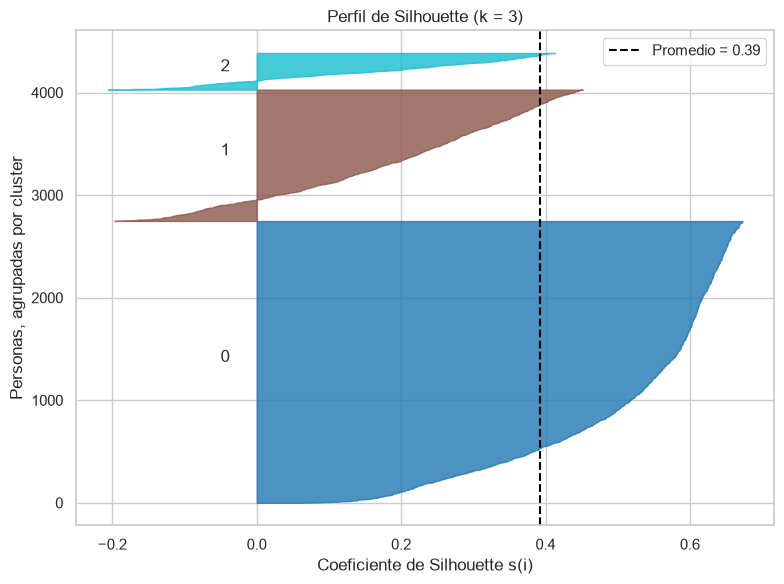

,% con Silhouette negativo
0,0.0
1,16.2
2,24.3


In [10]:
valores_s = silhouette_samples(X_base, kmeans_base.labels_)

fig, ax = plt.subplots(figsize=(8, 6))
inicio = 0
colores = plt.cm.tab10(np.linspace(0, 1, k_base))
for cluster in range(k_base):
    s_cluster = np.sort(valores_s[kmeans_base.labels_ == cluster])
    fin = inicio + len(s_cluster)
    ax.fill_betweenx(np.arange(inicio, fin), 0, s_cluster, color=colores[cluster], alpha=0.8)
    ax.text(-0.05, (inicio + fin) / 2, str(cluster))
    inicio = fin

ax.axvline(valores_s.mean(), color="black", linestyle="--", label=f"Promedio = {valores_s.mean():.2f}")
ax.set_xlabel("Coeficiente de Silhouette s(i)")
ax.set_ylabel("Personas, agrupadas por cluster")
ax.set_title(f"Perfil de Silhouette (k = {k_base})")
ax.legend()
plt.tight_layout()
plt.show()

# Porcentaje de personas con Silhouette negativo por cluster
neg = pd.Series(valores_s < 0).groupby(kmeans_base.labels_).mean().mul(100).round(1)
display(neg.to_frame("% con Silhouette negativo"))

> **Conclusión** El Silhouette promedio de 0,39 no es parejo entre grupos. El grupo 0, el más grande, es compacto y nadie tiene valores negativos. En los grupos 1 y 2, el 16,2% y el 24,3% de las personas están más cerca de otro grupo que del propio: son casos de frontera. Esto es esperable cuando la trayectoria profesional es un continuo y no hay saltos claros entre un perfil y otro, así que los límites de los grupos 1 y 2 hay que leerlos como aproximados.

### 5.4 Estabilidad: ¿el resultado depende de la semilla?

**Pregunta:** K-Means arranca con centros al azar. Si cambiamos la semilla, ¿obtenemos los mismos segmentos?

**Evidencia:** entrenamos 10 veces con distintas semillas y comparamos cada resultado con el modelo base usando el **Adjusted Rand Index (ARI)**, que vale 1 si dos agrupaciones son idénticas y cerca de 0 si coinciden como al azar. Probamos dos configuraciones:

* **Exigente:** `init="random"` y `n_init=1`, un solo intento con centros al azar.
* **La que usa nuestro modelo:** `k-means++` y `n_init=10`, que prueba diez inicializaciones y se queda con la mejor.

**Criterio:** la configuración que usa el modelo debe tener ARI promedio mayor a 0,8 para considerarlo estable. La exigente se muestra para ver cuánto ayuda `n_init`.

In [11]:
def ari_entre_semillas(X, k, referencia, **parametros):
    # ARI de 10 corridas con distinta semilla contra una agrupación de referencia
    resultados = []
    for semilla in range(10):
        etiquetas = KMeans(n_clusters=k, random_state=semilla, **parametros).fit_predict(X)
        resultados.append(adjusted_rand_score(referencia, etiquetas))
    return np.array(resultados)


ari_exigente = ari_entre_semillas(X_base, k_base, kmeans_base.labels_, init="random", n_init=1)
ari_usada = ari_entre_semillas(X_base, k_base, kmeans_base.labels_, init="k-means++", n_init=10)

estabilidad = pd.DataFrame({
    "semilla": range(10),
    "ARI (random, n_init=1)": ari_exigente,
    "ARI (k-means++, n_init=10)": ari_usada,
})
display(estabilidad.round(3))

print(f"ARI promedio configuración exigente : {ari_exigente.mean():.3f} (mínimo {ari_exigente.min():.3f})")
print(f"ARI promedio configuración del modelo: {ari_usada.mean():.3f} (mínimo {ari_usada.min():.3f})")
print("Decisión: el modelo es ESTABLE con la configuración usada (ARI promedio > 0,8)." if ari_usada.mean() > 0.8
      else "Atención: el modelo es poco estable incluso con n_init=10. Los segmentos dependen de la semilla y hay que interpretarlos con cautela.")

,semilla,"ARI (random, n_init=1)","ARI (k-means++, n_init=10)"
0,0,0.991,0.978
1,1,0.978,0.979
2,2,0.990,0.981
3,3,0.990,0.979
4,4,0.990,0.981
5,5,0.991,0.991
6,6,0.990,0.979
7,7,0.990,0.978
8,8,0.986,0.978
9,9,0.990,0.979


ARI promedio configuración exigente : 0.989 (mínimo 0.978)
ARI promedio configuración del modelo: 0.980 (mínimo 0.978)
Decisión: el modelo es ESTABLE con la configuración usada (ARI promedio > 0,8).


> **Conclusión** Al repetir el modelo con 10 semillas distintas se obtienen casi los mismos grupos: la coincidencia promedio es 0,98 sobre 1. Los segmentos no dependen del azar del algoritmo, así que se puede confiar en ellos.

### 5.5 Validación externa: ¿los segmentos se relacionan con el seniority?

**Pregunta:** no usamos `seniority` para agrupar. Si los segmentos reflejan trayectorias reales, deberían relacionarse con él.

**Evidencia:** tabla cruzada (cada fila suma 100%) y ARI contra `seniority`.

**Criterio:** no esperamos ARI cercano a 1. El seniority depende de muchas cosas además de los años (rol, empresa, criterio de cada persona), y los segmentos solo ven 4 variables de tiempo. Lo que buscamos es una relación **visible y con sentido** (más experiencia, más seniority) y que ningún segmento sea indistinguible del resto.

In [12]:
orden_seniority = ["Junior", "Semi-Senior", "Senior"]

tabla_sen = pd.crosstab(df_cl["cluster_base"], df_cl["seniority"], normalize="index").mul(100).round(1)
columnas_orden = [c for c in orden_seniority if c in tabla_sen.columns]
print("% de cada seniority dentro de cada cluster (modelo base):")
display(tabla_sen[columnas_orden])

ari_sen_base = adjusted_rand_score(df_cl["seniority"], df_cl["cluster_base"])
print(f"ARI entre clusters y seniority: {ari_sen_base:.3f}")

% de cada seniority dentro de cada cluster (modelo base):


seniority,Junior,Semi-Senior,Senior
cluster_base,,,
0,15.8,47.4,36.9
1,0.2,4.3,95.5
2,0.0,1.4,98.6


ARI entre clusters y seniority: 0.061


> **Conclusión** Los grupos se relacionan con el seniority de forma lógica, aunque no lo usamos para armarlos: los grupos 1 y 2 son casi todos Senior (95,5% y 98,6%), mientras que el grupo 0 mezcla los tres niveles (15,8% Junior, 47,4% Semi-Senior y 36,9% Senior). El ARI es bajo (0,06) porque los grupos no repiten la etiqueta de seniority: miran la trayectoria en años, que aporta información distinta a la que cada persona declara.

### 5.6 Mejora: ¿podemos mejorar los datos de entrada?

**Pregunta:** en el AED dejamos dos dudas abiertas: ¿conviene transformar con logaritmo las variables asimétricas? ¿conviene sacar `tengo_edad` por solaparse con la experiencia?

**Evidencia:** armamos tres versiones y, para cada una, repetimos el proceso completo (elegir k con el mismo criterio y medir):

| Versión | Variables | Transformación |
|---|---|---|
| **V1 Base** | Las 4 | Ninguna |
| **V2 Log** | Las 4 | `log1p` en las variables asimétricas del AED |
| **V3 Log sin edad** | Las 3 de trayectoria laboral | `log1p` en las asimétricas |

**Criterio:** se elige la versión con mayor Silhouette. Si varias quedan a menos de **0,02** de la mejor (empate técnico), se prefiere la **más simple**: menos variables y, a igualdad, menos transformaciones. Es el principio de parsimonia, el mismo que usamos para elegir `max_depth` en el notebook 04.

**Limitación a tener presente:** el Silhouette de versiones con distintas variables no es estrictamente comparable, porque cada una mide distancias en un espacio distinto. Por eso agregamos el margen de empate y miramos también el ARI contra `seniority`.

In [13]:
TOLERANCIA_EMPATE = 0.02


def preparar(datos, variables, log_vars=()):
    # Aplica log1p a las variables indicadas y escala todas con StandardScaler
    X = datos[variables].copy()
    for c in log_vars:
        X[c] = np.log1p(X[c])
    return StandardScaler().fit_transform(X)


# Definición de las versiones: nombre -> (variables, variables con log)
vars_sin_edad = [c for c in vars_cluster if c != "tengo_edad"]
versiones = {
    "V1 Base": (vars_cluster, []),
    "V2 Log": (vars_cluster, vars_sesgadas),
    "V3 Log sin edad": (vars_sin_edad, [c for c in vars_sesgadas if c != "tengo_edad"]),
}
if not vars_sesgadas:
    print("Nota: ninguna variable superó el umbral de asimetría, por lo que V2 es idéntica a V1.\n")

filas, matrices = [], {}
for nombre, (variables, log_vars) in versiones.items():
    X_v = preparar(df_cl, variables, log_vars)
    tab_v = evaluar_k(X_v)
    k_v = elegir_k(tab_v)
    etiquetas_v = KMeans(n_clusters=k_v, n_init=10, random_state=RANDOM_STATE).fit_predict(X_v)
    fila_k = tab_v[tab_v["k"] == k_v].iloc[0]
    matrices[nombre] = X_v
    filas.append({
        "Versión": nombre,
        "Variables": len(variables),
        "Con log": len(log_vars),
        "k elegido": k_v,
        "Silhouette": fila_k["silhouette"],
        "Cluster más chico (%)": fila_k["cluster_mas_chico_%"],
        "ARI vs seniority": adjusted_rand_score(df_cl["seniority"], etiquetas_v),
    })

tabla_versiones = pd.DataFrame(filas)
display(tabla_versiones.round(3))

# Criterio: mayor Silhouette; en empate técnico, la versión más simple
mejor_sil = tabla_versiones["Silhouette"].max()
candidatas = tabla_versiones[tabla_versiones["Silhouette"] >= mejor_sil - TOLERANCIA_EMPATE]
elegida = candidatas.sort_values(["Variables", "Con log"]).iloc[0]

version_final = elegida["Versión"]
vars_final, log_final = versiones[version_final]
X_final = matrices[version_final]
k_final = int(elegida["k elegido"])
sil_kmeans_final = float(elegida["Silhouette"])

# Modelo K-Means con la versión elegida y control de su estabilidad
km_final = KMeans(n_clusters=k_final, n_init=10, random_state=RANDOM_STATE).fit(X_final)
etiquetas_kmeans = km_final.labels_
ari_final = ari_entre_semillas(X_final, k_final, etiquetas_kmeans, init="k-means++", n_init=10)

print(f"\nVersiones en empate técnico (a menos de {TOLERANCIA_EMPATE} de la mejor): {list(candidatas['Versión'])}")
print(f"Decisión: se usa la versión '{version_final}' con k = {k_final} (Silhouette = {sil_kmeans_final:.3f}).")
print("Variables para agrupar:", vars_final)
print("Variables con log1p:", log_final if log_final else "ninguna")
print(f"Estabilidad de la versión elegida (ARI promedio entre 10 semillas): {ari_final.mean():.3f}")

,Versión,Variables,Con log,k elegido,Silhouette,Cluster más chico (%),ARI vs seniority
0,V1 Base,4,0,3,0.392,8.160,0.061
1,V2 Log,4,3,4,0.255,17.438,0.127
2,V3 Log sin edad,3,3,5,0.320,7.978,0.163



Versiones en empate técnico (a menos de 0.02 de la mejor): ['V1 Base']
Decisión: se usa la versión 'V1 Base' con k = 3 (Silhouette = 0.392).
Variables para agrupar: ['anos_de_experiencia', 'antiguedad_en_la_empresa_actual', 'anos_en_el_puesto_actual', 'tengo_edad']
Variables con log1p: ninguna
Estabilidad de la versión elegida (ARI promedio entre 10 semillas): 0.980


> **Conclusión:** Se probaron tres versiones de los datos y la original fue la mejor: Silhouette de 0,392 contra 0,255 (con logaritmo) y 0,320 (con logaritmo y sin edad). Ninguna quedó dentro del margen de empate de 0,02, así que transformar o quitar variables no mejoró la separación. El modelo final es el mismo que el base y sigue siendo estable (0,98). Las versiones con logaritmo coinciden más con el seniority (ARI de 0,13 y 0,16 contra 0,06), pero el criterio fijado de antemano era el Silhouette.

## Parte 6: DBSCAN

**Pregunta:** ¿un modelo basado en densidad encuentra una estructura mejor que K-Means?

**Cómo funciona DBSCAN:** para cada persona mira cuántas otras hay "cerca" (a una distancia menor a `eps`). Si hay al menos `min_samples`, esa persona está en una zona densa (punto *núcleo*). Los núcleos cercanos entre sí se encadenan y forman un grupo; las personas que no pertenecen a ninguna zona densa quedan como **ruido** (etiqueta -1), es decir, personas atípicas.

**Evidencia:** aplicamos DBSCAN sobre la **misma matriz** que quedó elegida en 5.6, para comparar en igualdad de condiciones. El procedimiento tiene tres pasos:

1. **Gráfico de distancias** al vecino número `min_samples` para ubicar un `eps` razonable. Como punto de partida, `min_samples` es el número de variables más uno.
2. **Tabla de sensibilidad** con varias combinaciones de `eps` y `min_samples`, porque DBSCAN es muy sensible a ellos.
3. **Silhouette** de cada combinación, dejando afuera el ruido.

**Criterio:** una combinación de DBSCAN es *aceptable* si:
* encuentra entre **2 y 6 clusters**,
* marca como ruido **a lo sumo el 10%** de las personas,
* su cluster más chico tiene al menos el **5%** de las personas (mismo piso que K-Means).

Como el Silhouette de DBSCAN no cuenta el ruido, la comparación le favorece. Por eso exigimos además el límite de ruido.

### 6.1 Gráfico de distancias para elegir `eps`

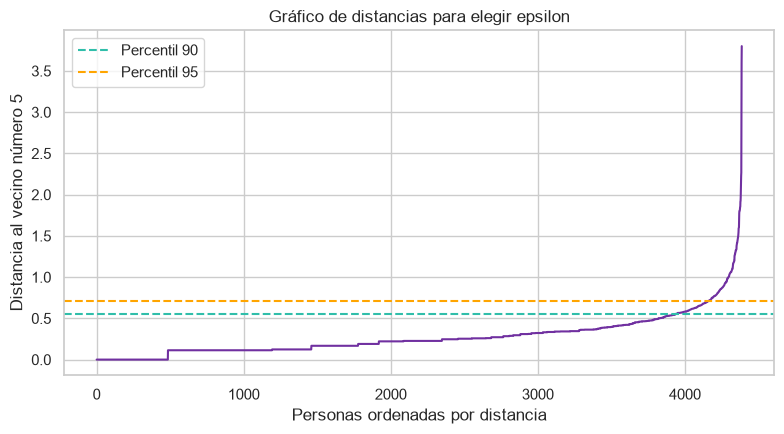

Distancia en el percentil 90: 0.56 | percentil 95: 0.72


In [14]:
# 1. Gráfico de distancias para ubicar eps
min_samples_base = len(vars_final) + 1

vecinos = NearestNeighbors(n_neighbors=min_samples_base).fit(X_final)
distancias, _ = vecinos.kneighbors(X_final)
dist_k = np.sort(distancias[:, -1])

plt.figure(figsize=(8, 4.5))
plt.plot(dist_k, color="#7030A0")
plt.axhline(np.percentile(dist_k, 90), color="#30BEAA", linestyle="--", label="Percentil 90")
plt.axhline(np.percentile(dist_k, 95), color="orange", linestyle="--", label="Percentil 95")
plt.xlabel("Personas ordenadas por distancia")
plt.ylabel(f"Distancia al vecino número {min_samples_base}")
plt.title("Gráfico de distancias para elegir epsilon")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Distancia en el percentil 90: {np.percentile(dist_k, 90):.2f} | percentil 95: {np.percentile(dist_k, 95):.2f}")

> **Conclusión** El gráfico muestra qué tan lejos tiene cada persona a su 5.º vecino más cercano. El 90% tiene su 5.º vecino a menos de 0,56 y la curva solo se dispara en el extremo derecho, donde están las personas más aisladas. El tramo plano del inicio aparece porque muchas personas tienen respuestas idénticas a otras (los años se responden en números enteros). Los percentiles 90 y 95 (0,56 y 0,72) son los valores de `eps` candidatos.

### 6.2 Tabla de sensibilidad y criterio de aceptación

In [15]:
# 2. Tabla de sensibilidad: eps x min_samples
valores_eps = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 1.0]
valores_ms = sorted(set([min_samples_base, 10, 20, 40]))

filas = []
for eps in valores_eps:
    for ms in valores_ms:
        etiquetas = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_final)
        mask = etiquetas != -1
        n_clusters = len(set(etiquetas[mask]))
        fila = {"eps": eps, "min_samples": ms, "clusters": n_clusters,
                "ruido_%": round((~mask).mean() * 100, 1),
                "cluster_mas_chico_%": np.nan, "cluster_mas_grande_%": np.nan, "silhouette": np.nan}
        if n_clusters >= 1:
            tamanos = np.bincount(etiquetas[mask]) / len(X_final) * 100
            fila["cluster_mas_chico_%"] = tamanos.min()
            fila["cluster_mas_grande_%"] = tamanos.max()
        if n_clusters >= 2:
            fila["silhouette"] = silhouette_score(X_final[mask], etiquetas[mask])
        filas.append(fila)

tabla_db = pd.DataFrame(filas)

print("Cantidad de clusters y % de ruido según eps y min_samples:")
display(tabla_db.pivot(index="eps", columns="min_samples", values=["clusters", "ruido_%"]))

# 3a. Combinaciones que pasan los dos primeros filtros (clusters y ruido)
primer_filtro = tabla_db[tabla_db["clusters"].between(2, 6) & (tabla_db["ruido_%"] <= 10)]
print("\nCombinaciones con 2 a 6 clusters y ruido <= 10% (antes de mirar el tamaño del cluster más chico):")
display(primer_filtro.round(3))

# 3b. Combinaciones aceptables según el criterio completo
aceptables = primer_filtro[primer_filtro["cluster_mas_chico_%"] >= 5]
print("Combinaciones de DBSCAN que cumplen el criterio completo:")
display(aceptables.round(3) if not aceptables.empty else "Ninguna combinación cumple el criterio.")

Cantidad de clusters y % de ruido según eps y min_samples:


clusters                  ruido_%                  
min_samples       5     10    20   40      5     10    20    40
eps                                                            
0.2             50.0  16.0  11.0  3.0    48.4  62.5  75.5  94.2
0.3             25.0   6.0   3.0  1.0    27.3  39.4  51.9  63.6
0.4             15.0   5.0   1.0  1.0    14.5  22.5  30.7  42.4
0.5              8.0   2.0   1.0  1.0     9.1  14.3  22.0  28.3
0.6              8.0   4.0   2.0  1.0     5.4   8.9  13.6  21.5
0.7              2.0   2.0   1.0  1.0     3.5   5.7   9.7  14.7
0.8              2.0   3.0   1.0  1.0     2.4   3.7   7.7  10.6
1.0              2.0   1.0   1.0  1.0     1.4   2.1   3.4   6.2


Combinaciones con 2 a 6 clusters y ruido <= 10% (antes de mirar el tamaño del cluster más chico):


,eps,min_samples,clusters,ruido_%,cluster_mas_chico_%,cluster_mas_grande_%,silhouette
17,0.6,10,4,8.9,0.182,90.289,0.437
20,0.7,5,2,3.5,0.410,96.125,0.610
21,0.7,10,2,5.7,0.182,94.119,0.490
24,0.8,5,2,2.4,0.182,97.447,0.642
25,0.8,10,3,3.7,0.182,95.874,0.559
28,1.0,5,2,1.4,0.114,98.496,0.645


Combinaciones de DBSCAN que cumplen el criterio completo:


'Ninguna combinación cumple el criterio.'

> **Conclusión** Ninguna combinación cumple el criterio. Con `eps` chico, DBSCAN fragmenta a la gente en muchos grupos y deja como ruido hasta el 94%; con `eps` grande, junta casi todo en un único bloque. Las 6 combinaciones que pasan el filtro de ruido encuentran de 2 a 4 grupos, pero uno contiene entre 90% y 98% de las personas y el más chico tiene apenas entre 5 y 18 personas. Sus Silhouette altos (0,44 a 0,65) engañan: miden un bloque gigante y un puñado de personas muy alejadas. Los datos forman un continuo, sin zonas densas separadas por vacíos.

### 6.3 DBSCAN como detector de personas atípicas

Aunque DBSCAN no sirva para segmentar a toda la muestra, tiene una ventaja: **marca como ruido a las personas más aisladas**. Eso responde a otra pregunta útil: ¿quiénes tienen trayectorias atípicas?

**Configuración que usamos:**
* Si alguna combinación fue aceptable en 6.2, usamos la de mayor Silhouette.
* Si ninguna lo fue, usamos como referencia `eps` en el **percentil 95** del gráfico de distancias (deja afuera cerca del 5% más aislado) y `min_samples` base.

In [16]:
if not aceptables.empty:
    mejor_db = aceptables.loc[aceptables["silhouette"].idxmax()]
    eps_db, ms_db = float(mejor_db["eps"]), int(mejor_db["min_samples"])
    origen_db = "mejor combinación aceptable"
else:
    eps_db, ms_db = float(np.percentile(dist_k, 95)), min_samples_base
    origen_db = "referencia (ninguna combinación fue aceptable)"

etiquetas_dbscan = DBSCAN(eps=eps_db, min_samples=ms_db).fit_predict(X_final)
es_ruido = etiquetas_dbscan == -1

print(f"DBSCAN con eps = {eps_db:.2f} y min_samples = {ms_db} ({origen_db})")
print(f"Clusters encontrados: {len(set(etiquetas_dbscan[~es_ruido]))}")
print(f"Personas en cada cluster: {np.bincount(etiquetas_dbscan[~es_ruido]).tolist()}")
print(f"Personas marcadas como ruido (atípicas): {es_ruido.sum()} ({es_ruido.mean() * 100:.1f}%)")

# Perfil de las personas atípicas frente al resto
perfil_ruido = df_cl.assign(grupo=np.where(es_ruido, "Atípicas (ruido)", "Resto")).groupby("grupo").agg(
    personas=("salario", "size"),
    experiencia=("anos_de_experiencia", "mean"),
    antiguedad_empresa=("antiguedad_en_la_empresa_actual", "mean"),
    anos_en_puesto=("anos_en_el_puesto_actual", "mean"),
    edad=("tengo_edad", "mean"),
    salario_mediana=("salario", "median"),
)
display(perfil_ruido.style.format({"experiencia": "{:.1f}", "antiguedad_empresa": "{:.1f}", "anos_en_puesto": "{:.1f}",
                                   "edad": "{:.1f}", "salario_mediana": formato_moneda}))

print("% de cada seniority en cada grupo:")
display(pd.crosstab(np.where(es_ruido, "Atípicas (ruido)", "Resto"), df_cl["seniority"], normalize="index").mul(100).round(1))

DBSCAN con eps = 0.72 y min_samples = 5 (referencia (ninguna combinación fue aceptable))
Clusters encontrados: 2
Personas en cada cluster: [4222, 18]
Personas marcadas como ruido (atípicas): 147 (3.4%)


,personas,experiencia,antiguedad_empresa,anos_en_puesto,edad,salario_mediana
grupo,,,,,,
Atípicas (ruido),147,25.4,16.1,13.2,55.2,"$3.400.000,00"
Resto,4240,9.5,4.1,3.3,36.5,"$3.235.028,50"


% de cada seniority en cada grupo:


seniority,Junior,Semi-Senior,Senior
row_0,,,
Atípicas (ruido),1.4,4.1,94.6
Resto,10.2,32.0,57.8


> **Conclusión** Aunque DBSCAN no sirve para segmentar, sí detecta a 147 personas atípicas (3,4%). Son trayectorias muy largas: en promedio 25 años de experiencia, 16 en la misma empresa, 13 en el mismo puesto y 55 años de edad (contra 9,5, 4,1, 3,3 y 36 del resto), y el 94,6% es Senior. Su mediana salarial es parecida a la del resto ($3,4 M contra $3,2 M). Es decir, lo atípico acá es la permanencia extrema, no el sueldo.

## Parte 7: Clustering jerárquico

**Cómo funciona (aglomerativo, de abajo hacia arriba):**
1. Cada persona empieza siendo **su propio grupo**.
2. Se unen los **dos grupos más parecidos**.
3. Se repite hasta que queda un único grupo con todas las personas.
4. El historial de uniones es un árbol, el **dendrograma**: las hojas son las personas y la **altura de cada unión** indica qué tan distintos eran los dos grupos que se unieron (unión baja = muy parecidos, unión alta = muy diferentes).
5. **Cortar** el árbol con una línea horizontal define los grupos: cortar más abajo da más grupos y más chicos; cortar más arriba, pocos grupos grandes.

A diferencia de DBSCAN no deja a nadie sin grupo, y a diferencia de K-Means no obliga a fijar `k` de entrada: se decide mirando el árbol y las métricas.

### 7.1 Tipos de enlace: cómo medir la distancia entre dos *grupos*

Cuando un grupo ya tiene varias personas, hay que definir cómo se mide su distancia a otro grupo. Eso es el **enlace**:

| Enlace | Distancia entre dos grupos | Comportamiento típico |
|---|---|---|
| **Single** | La menor distancia entre una persona de cada grupo | "Efecto cadena": un grupo gigante más personas sueltas |
| **Complete** | La mayor distancia entre una persona de cada grupo | Grupos compactos, pero muy sensible a extremos |
| **Average** | El promedio de todas las distancias entre pares | Intermedio entre los dos anteriores |
| **Ward** | Une los grupos cuya fusión aumenta menos la dispersión interna | Grupos compactos y de tamaño parejo; es el equivalente jerárquico de K-Means |

**Evidencia:** cortamos los cuatro árboles en el mismo número de grupos que K-Means (`k_final`) y miramos el Silhouette y **cuántas personas quedan en cada grupo**.

**Criterio:** un enlace sirve para segmentar solo si sus grupos tienen tamaños útiles (el más chico, al menos 5%). Un Silhouette alto con un grupo gigante y grupos de una sola persona no es un buen resultado.

Los cuatro enlaces cortados en 3 grupos:


,silhouette,cluster más grande (%),cluster más chico (%),personas por cluster
enlace,,,,
single,0.500,99.909,0.023,"[4383, 3, 1]"
complete,0.531,96.353,1.163,"[4227, 109, 51]"
average,0.595,98.974,0.342,"[4342, 30, 15]"
ward,0.340,54.935,11.147,"[2410, 1488, 489]"


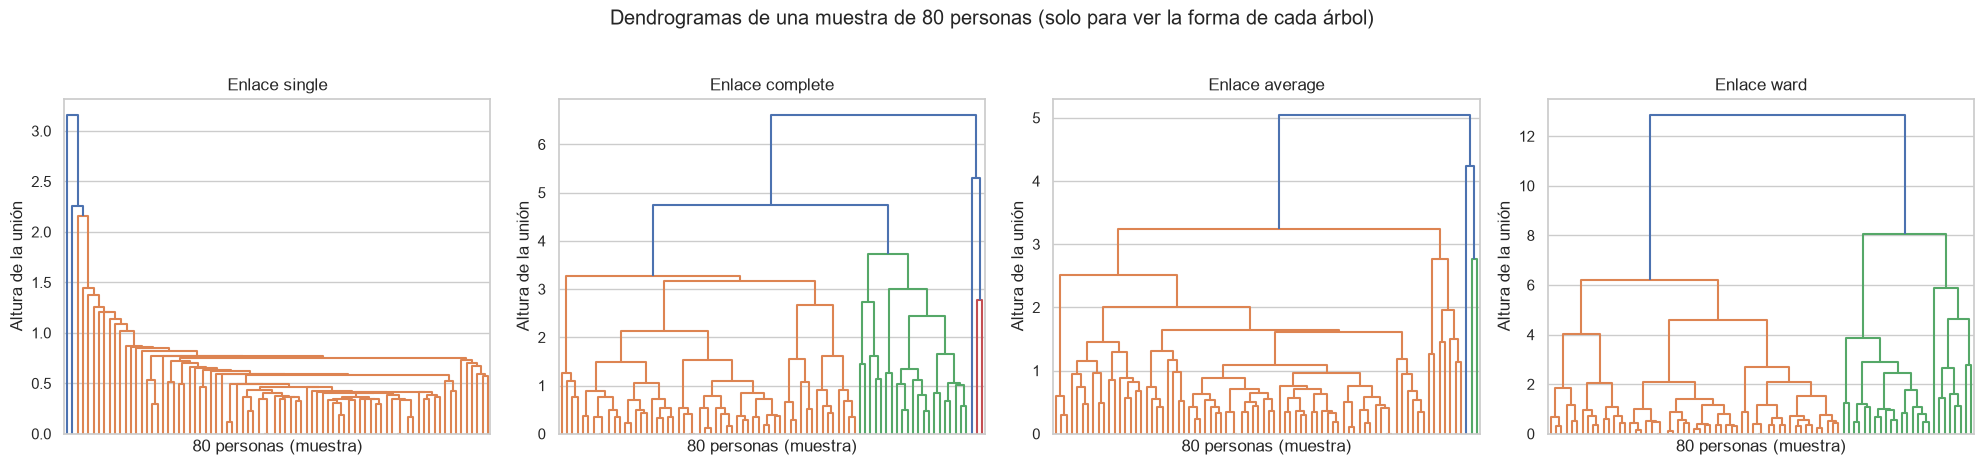

In [17]:
enlaces = ["single", "complete", "average", "ward"]
Z = {metodo: linkage(X_final, method=metodo) for metodo in enlaces}   # árboles calculados con todas las personas

filas, etiquetas_enlace = [], {}
for metodo in enlaces:
    etiquetas = fcluster(Z[metodo], t=k_final, criterion="maxclust") - 1
    etiquetas_enlace[metodo] = etiquetas
    tamanos = np.bincount(etiquetas)
    filas.append({
        "enlace": metodo,
        "silhouette": silhouette_score(X_final, etiquetas),
        "cluster más grande (%)": tamanos.max() / len(X_final) * 100,
        "cluster más chico (%)": tamanos.min() / len(X_final) * 100,
        "personas por cluster": sorted(tamanos.tolist(), reverse=True),
    })

comparacion_enlaces = pd.DataFrame(filas).set_index("enlace")
print(f"Los cuatro enlaces cortados en {k_final} grupos:")
display(comparacion_enlaces.round(3))

# Forma de cada árbol, dibujada con una muestra de 80 personas (solo para poder verlo)
muestra = np.random.RandomState(RANDOM_STATE).choice(len(X_final), 80, replace=False)
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, metodo in zip(axes, enlaces):
    dendrogram(linkage(X_final[muestra], method=metodo), ax=ax, no_labels=True)
    ax.set_title(f"Enlace {metodo}")
    ax.set_xlabel("80 personas (muestra)")
    ax.set_ylabel("Altura de la unión")
plt.suptitle("Dendrogramas de una muestra de 80 personas (solo para ver la forma de cada árbol)", y=1.03)
plt.tight_layout()
plt.show()

> **Conclusión** Con tres de los cuatro enlaces (single, complete y average) el árbol arma un grupo gigante (96% a 99,9% de las personas) y grupos chicos de entre 1 y 109 personas. Su Silhouette parece alto (0,50 a 0,60) pero es un espejismo: separan a unos pocos extremos y dejan al resto junto. Solo Ward reparte a las personas en grupos de tamaño útil (2.410, 1.488 y 489), con un Silhouette más bajo (0,34) pero real. Los dendrogramas lo confirman: single parece una escalera, y Ward muestra ramas grandes bien diferenciadas.

### 7.2 Elección del corte del dendrograma (enlace Ward)

**Pregunta:** ¿en cuántos grupos cortamos el árbol?

**Evidencia:** la altura de las últimas uniones (un salto grande indica que se están uniendo grupos muy distintos, y ahí conviene cortar) y el Silhouette para cada cantidad de grupos.

**Criterio:** el mismo que usamos para K-Means (k entre 3 y 6, ningún grupo menor al 5% y mayor Silhouette), para que la comparación sea justa.

,k,altura de la unión,silhouette,cluster_mas_chico_%
0,2,109.087,0.343,45.065
1,3,74.331,0.340,11.147
2,4,51.223,0.349,3.670
3,5,43.509,0.319,3.670
4,6,31.988,0.319,2.325
5,7,31.485,0.189,2.325
6,8,31.170,0.202,2.325
7,9,28.765,0.209,1.299
8,10,24.395,0.209,1.299


Decisión: se corta el árbol Ward en k = 3 grupos.


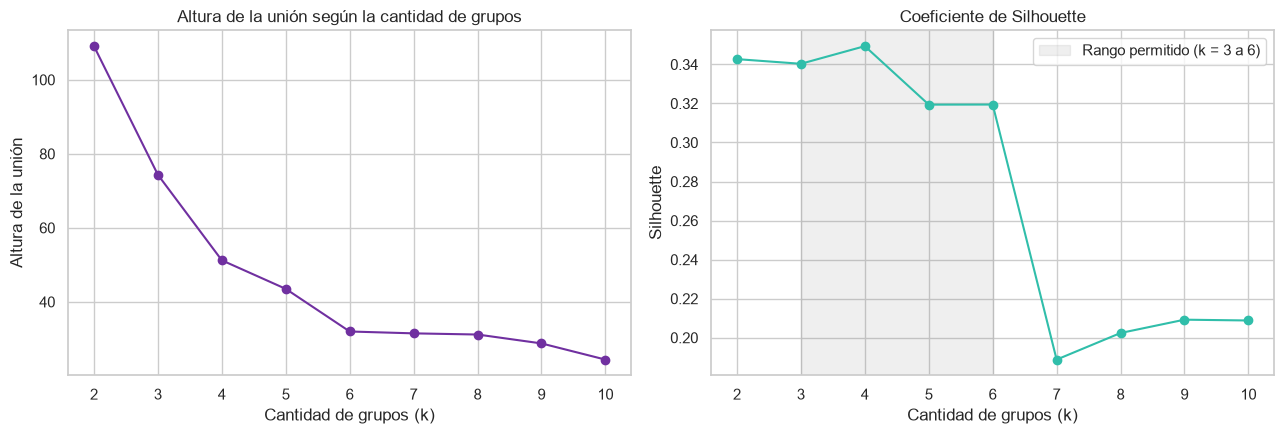

In [18]:
Z_ward = Z["ward"]

# Altura a la que se pasa de k grupos a k-1 (cuanto más alta, más distintos eran los grupos que se unieron)
alturas = {k: Z_ward[-(k - 1), 2] for k in range(2, 11)}

filas = []
for k in range(2, 11):
    etiquetas = fcluster(Z_ward, t=k, criterion="maxclust") - 1
    filas.append({
        "k": k,
        "altura de la unión": alturas[k],
        "silhouette": silhouette_score(X_final, etiquetas),
        "cluster_mas_chico_%": np.bincount(etiquetas).min() / len(X_final) * 100,
    })
tabla_ward = pd.DataFrame(filas)
display(tabla_ward.round(3))

k_ward = elegir_k(tabla_ward)
print(f"Decisión: se corta el árbol Ward en k = {k_ward} grupos.")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(tabla_ward["k"], tabla_ward["altura de la unión"], "o-", color="#7030A0")
ax[0].set_title("Altura de la unión según la cantidad de grupos")
ax[0].set_xlabel("Cantidad de grupos (k)")
ax[0].set_ylabel("Altura de la unión")

ax[1].plot(tabla_ward["k"], tabla_ward["silhouette"], "o-", color="#30BEAA")
ax[1].axvspan(K_MIN, K_MAX, color="gray", alpha=0.12, label=f"Rango permitido (k = {K_MIN} a {K_MAX})")
ax[1].set_title("Coeficiente de Silhouette")
ax[1].set_xlabel("Cantidad de grupos (k)")
ax[1].set_ylabel("Silhouette")
ax[1].legend()
plt.tight_layout()
plt.show()

> **Conclusión** Se corta el árbol Ward en 3 grupos. La altura de las uniones cae fuerte entre 2 y 4 grupos (de 109 a 51) y después se aplana. Con 4 grupos el Silhouette sube un poco (0,349), pero el grupo más chico queda en 3,7%, bajo el piso del 5%. Con k = 3 el Silhouette es 0,340 y el grupo más chico tiene 11,1%. Es la misma cantidad de grupos que eligió K-Means.

### 7.3 Dendrograma completo y perfil de los grupos

Ahora sí el árbol Ward con **todas** las personas. Para que sea legible se dibuja truncado: se muestran las últimas 20 uniones y, entre paréntesis, cuántas personas contiene cada rama final. La línea roja marca el corte elegido.

**EDA posterior al modelo:** describimos los grupos de Ward en unidades originales y los cruzamos con los de K-Means para ver cuánto coinciden.

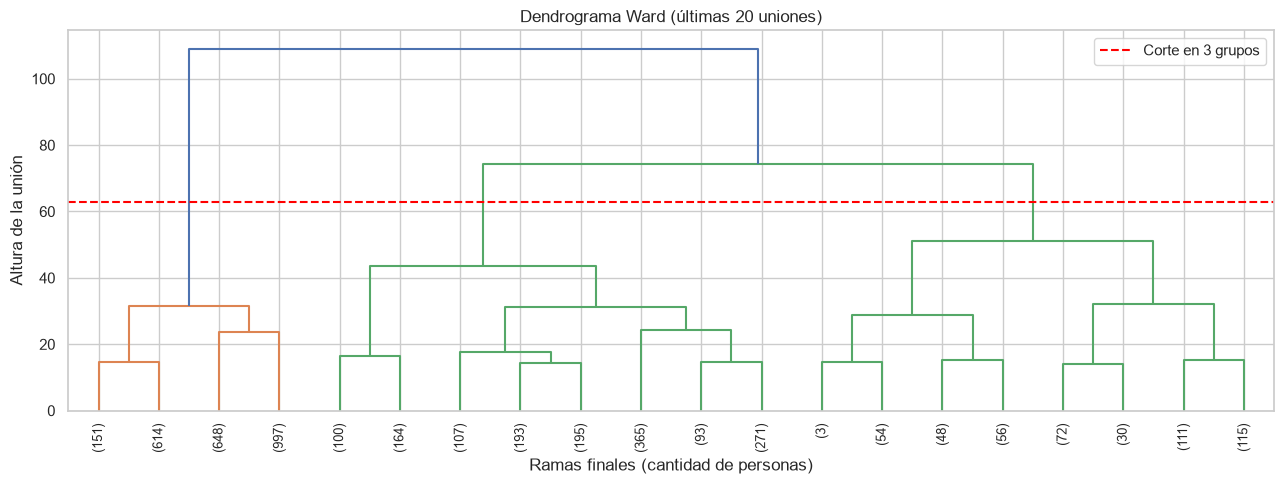

Perfil de cada grupo del jerárquico (Ward):


,personas,experiencia,antiguedad_empresa,anos_en_puesto,edad,salario_mediana
grupo_ward,,,,,,
0,2410,4.9,2.6,2.4,30.9,"$2.800.000,00"
1,1488,15.3,4.0,3.6,44.1,"$4.000.000,00"
2,489,18.9,15.8,9.4,46.0,"$3.600.000,00"


Cruce entre los grupos de K-Means (filas) y los de Ward (columnas), en cantidad de personas:


Ward,0,1,2
K-Means,,,
0,2383,325,40
1,27,1108,146
2,0,55,303


ARI entre K-Means y Ward: 0.653


In [31]:
etiquetas_ward = fcluster(Z_ward, t=k_ward, criterion="maxclust") - 1
altura_corte = (Z_ward[-(k_ward - 1), 2] + Z_ward[-k_ward, 2]) / 2

plt.figure(figsize=(13, 5))
dendrogram(Z_ward, truncate_mode="lastp", p=20, show_leaf_counts=True, leaf_rotation=90, leaf_font_size=9)
plt.axhline(altura_corte, color="red", linestyle="--", label=f"Corte en {k_ward} grupos")
plt.title("Dendrograma Ward (últimas 20 uniones)")
plt.xlabel("Ramas finales (cantidad de personas)")
plt.ylabel("Altura de la unión")
plt.legend()
plt.tight_layout()
plt.show()

# Perfil de cada grupo de Ward en unidades originales
perfil_ward = df_cl.assign(grupo_ward=etiquetas_ward).groupby("grupo_ward").agg(
    personas=("salario", "size"),
    experiencia=("anos_de_experiencia", "mean"),
    antiguedad_empresa=("antiguedad_en_la_empresa_actual", "mean"),
    anos_en_puesto=("anos_en_el_puesto_actual", "mean"),
    edad=("tengo_edad", "mean"),
    salario_mediana=("salario", "median"),
)
print("Perfil de cada grupo del jerárquico (Ward):")
display(perfil_ward.style.format({"experiencia": "{:.1f}", "antiguedad_empresa": "{:.1f}", "anos_en_puesto": "{:.1f}",
                                  "edad": "{:.1f}", "salario_mediana": formato_moneda}))

# Cruce con K-Means: ¿las mismas personas caen en los mismos grupos?
print("Cruce entre los grupos de K-Means (filas) y los de Ward (columnas), en cantidad de personas:")
display(pd.crosstab(etiquetas_kmeans, etiquetas_ward, rownames=["K-Means"], colnames=["Ward"]))
print(f"ARI entre K-Means y Ward: {adjusted_rand_score(etiquetas_kmeans, etiquetas_ward):.3f}")

> **Conclusión** El jerárquico cuenta una historia parecida a la de K-Means: un grupo grande de trayectoria corta (2.410 personas, 4,9 años de experiencia), otro de trayectoria larga (1.488 personas, 15,3 años) y otro de mucha permanencia en la empresa (489 personas, 15,8 años en la misma empresa). Coinciden en gran parte con K-Means (ARI de 0,65): por ejemplo, 2.383 de las 2.748 personas del grupo 0 de K-Means también están en el grupo 0 de Ward. Las diferencias están en los bordes, sobre todo en la zona intermedia.

## Parte 8: Comparación de modelos y decisión final

**Pregunta:** ¿con cuál de los tres modelos nos quedamos?

**Evidencia:** una tabla con los tres modelos medidos con las mismas métricas. En DBSCAN el Silhouette no incluye al ruido; por eso se informa también el porcentaje de ruido.

**Criterio** (definido antes de ver los resultados):
1. Un modelo es **elegible** si tiene entre 2 y 6 clusters, a lo sumo 10% de ruido y su cluster más chico tiene al menos 5% de las personas.
2. Entre los elegibles, gana el de **mayor Silhouette**.
3. Si varios quedan a menos de **0,02** de la mejor (empate técnico), se prefiere en este orden: **K-Means** (cada grupo tiene un perfil promedio fácil de explicar y permite asignar personas nuevas), luego el jerárquico y por último DBSCAN.

In [20]:
etiquetas_modelos = {
    "K-Means": etiquetas_kmeans,
    "DBSCAN": etiquetas_dbscan,
    "Jerárquico (Ward)": etiquetas_ward,
}
parametros = {
    "K-Means": f"k = {k_final}, versión '{version_final}'",
    "DBSCAN": f"eps = {eps_db:.2f}, min_samples = {ms_db}",
    "Jerárquico (Ward)": f"corte en k = {k_ward}",
}
orden_preferencia = ["K-Means", "Jerárquico (Ward)", "DBSCAN"]

filas = []
for nombre, etiquetas in etiquetas_modelos.items():
    asignadas = etiquetas != -1
    n_clusters = len(set(etiquetas[asignadas]))
    tamanos = np.bincount(etiquetas[asignadas]) / len(etiquetas) * 100
    ruido = (~asignadas).mean() * 100
    filas.append({
        "Modelo": nombre,
        "Parámetros": parametros[nombre],
        "Clusters": n_clusters,
        "Ruido (%)": ruido,
        "Cluster más chico (%)": tamanos.min(),
        "Silhouette": silhouette_score(X_final[asignadas], etiquetas[asignadas]) if n_clusters >= 2 else np.nan,
        "ARI vs seniority": adjusted_rand_score(df_cl["seniority"][asignadas], etiquetas[asignadas]),
        "ARI vs K-Means": adjusted_rand_score(etiquetas_kmeans[asignadas], etiquetas[asignadas]),
        "Elegible": (2 <= n_clusters <= 6) and ruido <= 10 and tamanos.min() >= MIN_PCT_CLUSTER,
    })
comparacion = pd.DataFrame(filas).set_index("Modelo")
display(comparacion.round(3))

# Decisión según el criterio
elegibles = comparacion[comparacion["Elegible"]]
if elegibles.empty:
    algoritmo_final = "K-Means"
    motivo = "ningún modelo cumple las condiciones de elegibilidad; se mantiene el modelo principal."
else:
    mejor_sil = elegibles["Silhouette"].max()
    empatados = elegibles[elegibles["Silhouette"] >= mejor_sil - TOLERANCIA_EMPATE].index
    algoritmo_final = min(empatados, key=orden_preferencia.index)
    if len(empatados) == 1:
        motivo = f"es el modelo elegible con mayor Silhouette ({mejor_sil:.3f}), sin empate técnico."
    else:
        motivo = (f"hay empate técnico entre {list(empatados)} (a menos de {TOLERANCIA_EMPATE} de {mejor_sil:.3f}); "
                  "se aplica el orden de preferencia.")

no_elegibles = list(comparacion.index[~comparacion["Elegible"]])
print(f"Modelos que no cumplen la elegibilidad: {no_elegibles if no_elegibles else 'ninguno'}")
print(f"Algoritmo final: {algoritmo_final}")
print(f"Motivo: {motivo}")

# El modelo final queda guardado en df_cl["cluster"]
df_cl["cluster"] = etiquetas_modelos[algoritmo_final]
descripcion_modelo = f"{algoritmo_final} ({parametros[algoritmo_final]})"
sil_final = comparacion.loc[algoritmo_final, "Silhouette"]
print(f"\nModelo final: {descripcion_modelo}")
display(df_cl["cluster"].value_counts().sort_index().to_frame("personas"))

,Parámetros,Clusters,Ruido (%),Cluster más chico (%),Silhouette,ARI vs seniority,ARI vs K-Means,Elegible
Modelo,,,,,,,,
K-Means,"k = 3, versión 'V1 Base'",3,0.000,8.160,0.392,0.061,1.000,True
DBSCAN,"eps = 0.72, min_samples = 5",2,3.351,0.410,0.609,-0.004,0.016,False
Jerárquico (Ward),corte en k = 3,3,0.000,11.147,0.340,0.094,0.653,True


Modelos que no cumplen la elegibilidad: ['DBSCAN']
Algoritmo final: K-Means
Motivo: es el modelo elegible con mayor Silhouette (0.392), sin empate técnico.

Modelo final: K-Means (k = 3, versión 'V1 Base')


,personas
cluster,
0,2748
1,1281
2,358


> **Conclusión** K-Means es el modelo final. DBSCAN queda descartado porque no segmenta: un grupo concentra el 96% de las personas y el más chico tiene 0,4%, y su Silhouette alto (0,61) engaña porque deja afuera al ruido. K-Means y el jerárquico Ward son elegibles, y K-Means tiene mayor Silhouette (0,392 contra 0,340, una diferencia mayor al margen de empate de 0,02). Además ambos agrupan de forma parecida (ARI de 0,65), lo que indica que la estructura de tres grupos no depende del método. El modelo final tiene los mismos grupos que el modelo base.

## Parte 9: Visualización y reducción de dimensiones: PCA y SVD

Con 3 o 4 variables no podemos graficar a las personas en un plano. **PCA** resume las variables en "variables nuevas" (componentes) ordenadas de la que más diferencia a las personas a la que menos. Con las dos primeras componentes podemos dibujar un plano en 2D.

**Aclaración importante:** PCA no forma grupos. Solo cambia el sistema de coordenadas para poder dibujar. Los grupos ya los formaron los algoritmos con todas las variables.

### 9.1 PCA: cuánta información resume cada componente

**Criterio:** miramos la **varianza explicada** (qué porcentaje de las diferencias entre personas recoge cada componente) y cuántas componentes hacen falta para tener un resumen razonable.

,varianza explicada (%),varianza acumulada (%)
Componente 1,62.6,62.6
Componente 2,18.7,81.4
Componente 3,12.2,93.5
Componente 4,6.5,100.0


Peso de cada variable en las dos primeras componentes:


,anos_de_experiencia,antiguedad_en_la_empresa_actual,anos_en_el_puesto_actual,tengo_edad
Componente 1,0.54,0.47,0.46,0.52
Componente 2,-0.40,0.48,0.57,-0.53


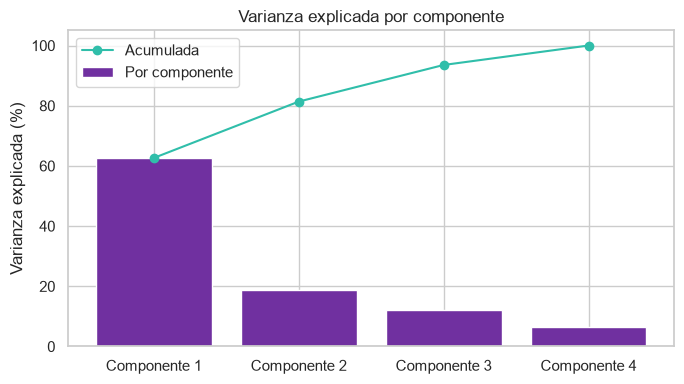

In [21]:
pca = PCA(random_state=RANDOM_STATE).fit(X_final)
Z_pca = pca.transform(X_final)
var_exp = pca.explained_variance_ratio_

componentes = [f"Componente {i + 1}" for i in range(len(var_exp))]
tabla_var = pd.DataFrame({"varianza explicada (%)": var_exp * 100,
                          "varianza acumulada (%)": np.cumsum(var_exp) * 100}, index=componentes)
display(tabla_var.round(1))

print("Peso de cada variable en las dos primeras componentes:")
display(pd.DataFrame(pca.components_[:2], columns=vars_final, index=["Componente 1", "Componente 2"]).round(2))

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(componentes, var_exp * 100, color="#7030A0", label="Por componente")
ax.plot(componentes, np.cumsum(var_exp) * 100, "o-", color="#30BEAA", label="Acumulada")
ax.set_ylabel("Varianza explicada (%)")
ax.set_title("Varianza explicada por componente")
ax.legend()
plt.tight_layout()
plt.show()

> **Conclusión** Las 4 variables se resumen bien en 2 componentes: la primera recoge el 62,6% de las diferencias entre personas y la segunda el 18,7% (81,4% entre las dos). La primera pesa casi igual a las cuatro variables, así que funciona como un índice general de trayectoria (más años en todo). La segunda contrasta experiencia y edad contra antigüedad y años en el puesto, es decir, distingue a quien acumuló carrera en distintos lugares de quien permaneció mucho en el mismo.

### 9.2 Los segmentos en el plano de las dos primeras componentes

Dibujamos a cada persona en el plano y la coloreamos de cuatro maneras: por **seniority** (una variable que el modelo no usó) y por el grupo que le asignó cada algoritmo. Si los grupos se ven separados, es una señal de que la estructura es real; si se mezclan, conviene mirar el resultado con cautela. Los colores de cada panel son independientes entre sí.

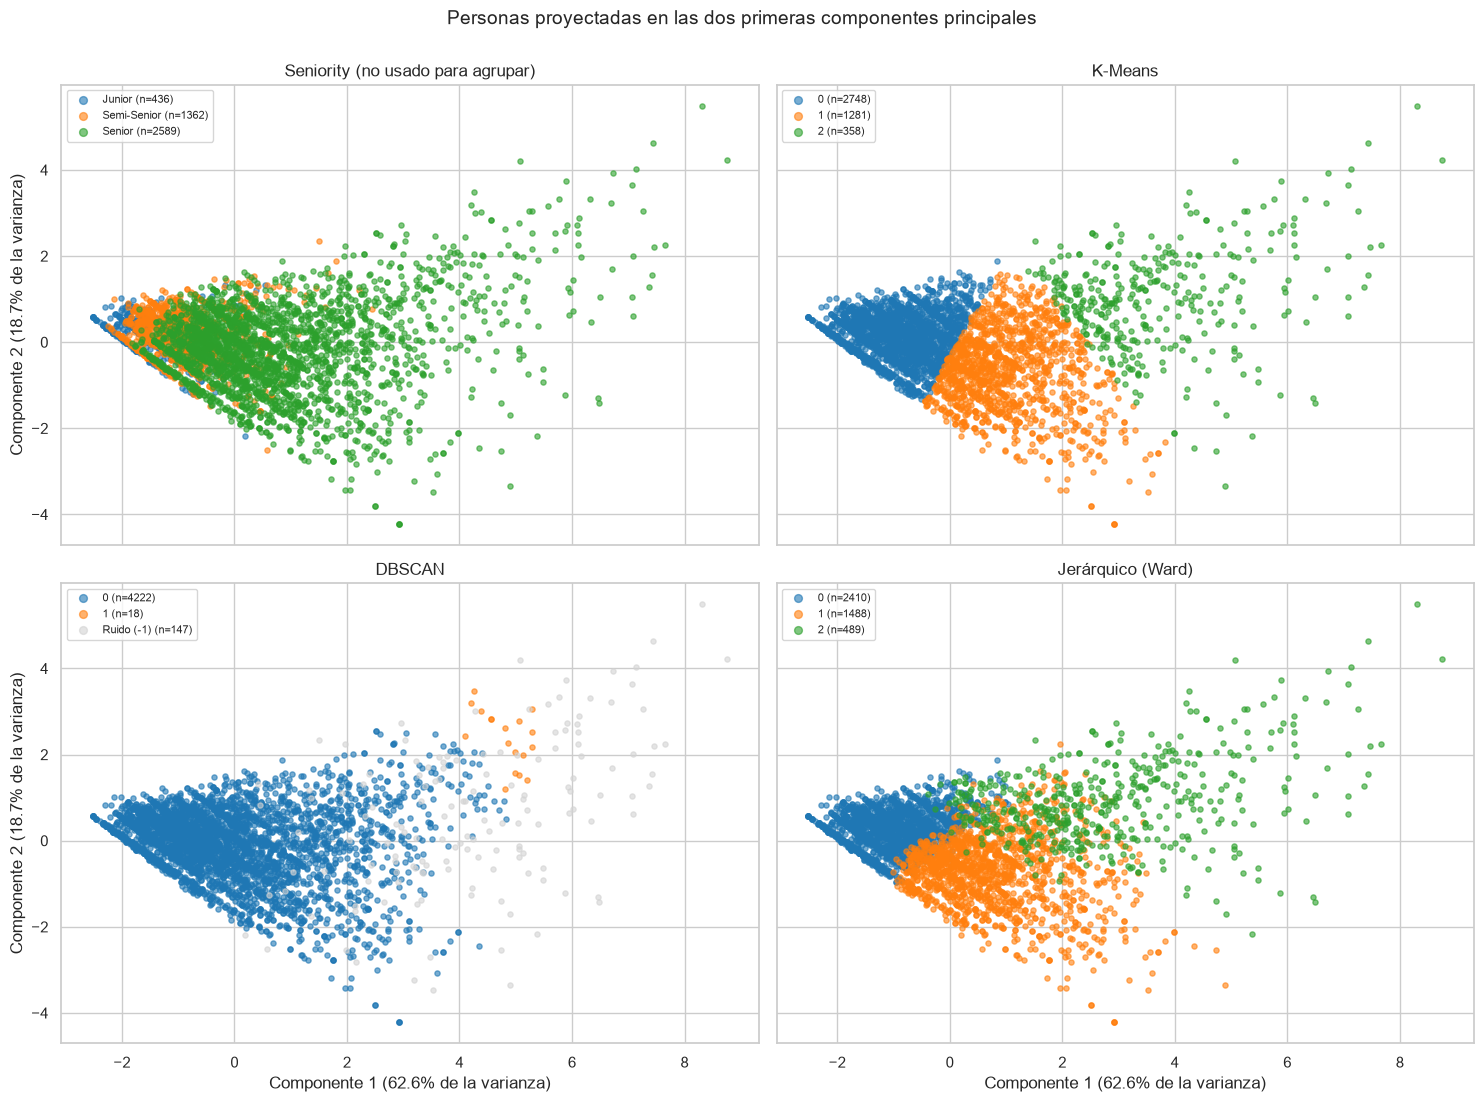

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11), sharex=True, sharey=True)
paneles = [("Seniority (no usado para agrupar)", df_cl["seniority"].values)] + \
          [(f"{nombre}", etiquetas) for nombre, etiquetas in etiquetas_modelos.items()]

for ax, (titulo, valores) in zip(axes.ravel(), paneles):
    categorias = sorted(pd.unique(valores), key=lambda v: (str(v) == "-1", str(v)))
    for i, cat in enumerate(categorias):
        m = valores == cat
        etiqueta = "Ruido (-1)" if str(cat) == "-1" else f"{cat}"
        color = "lightgray" if str(cat) == "-1" else plt.cm.tab10(i % 10)
        ax.scatter(Z_pca[m, 0], Z_pca[m, 1], s=14, alpha=0.6, color=color, label=f"{etiqueta} (n={m.sum()})")
    ax.set_title(titulo)
    ax.legend(fontsize=8, markerscale=1.5)
for ax in axes[1]:
    ax.set_xlabel(f"Componente 1 ({var_exp[0] * 100:.1f}% de la varianza)")
for ax in axes[:, 0]:
    ax.set_ylabel(f"Componente 2 ({var_exp[1] * 100:.1f}% de la varianza)")
plt.suptitle("Personas proyectadas en las dos primeras componentes principales", fontsize=14, y=1.0)
plt.tight_layout()
plt.show()

> **Conclusión** En el plano, las personas forman una nube continua, sin islas separadas. Los grupos de K-Means se ven como franjas ordenadas de izquierda (trayectoria corta) a derecha (trayectoria larga), y Ward reparte en franjas parecidas. DBSCAN deja casi todo en un único bloque y marca como ruido a las personas del extremo derecho. El seniority sigue el mismo orden: Junior y Semi-Senior a la izquierda, Senior hacia la derecha. El borde diagonal del lado izquierdo aparece porque las variables no pueden ser menores a cero años.

### 9.3 SVD: la misma idea desde otro ángulo

La **descomposición en valores singulares (SVD)** factoriza la matriz de datos en tres partes. Cuando se aplica a la matriz **centrada** (a cada columna se le resta su promedio), da exactamente lo mismo que PCA. **TruncatedSVD** hace lo mismo sin centrar, y está pensada para matrices muy grandes y con muchos ceros.

**Evidencia:** verificamos con nuestros datos que la SVD "a mano" coincide con PCA y comparamos con `TruncatedSVD`.

In [23]:
# SVD "a mano" de la matriz centrada
X_centrada = X_final - X_final.mean(axis=0)
U, S, Vt = np.linalg.svd(X_centrada, full_matrices=False)

print("¿La SVD de la matriz centrada da la misma varianza explicada que PCA?",
      np.allclose(S ** 2 / (len(X_final) - 1), pca.explained_variance_))
print("¿Mismas coordenadas en 2 componentes (salvo el signo)?",
      np.allclose(np.abs((U * S)[:, :2]), np.abs(Z_pca[:, :2]), atol=1e-6))

# TruncatedSVD (sin centrar)
svd = TruncatedSVD(n_components=2, random_state=RANDOM_STATE).fit(X_final)
comparacion_svd = pd.DataFrame({
    "PCA": [var_exp[:2].sum() * 100],
    "TruncatedSVD (sin centrar)": [svd.explained_variance_ratio_.sum() * 100],
}, index=["Varianza explicada con 2 componentes (%)"])
display(comparacion_svd.round(1))

¿La SVD de la matriz centrada da la misma varianza explicada que PCA? True
¿Mismas coordenadas en 2 componentes (salvo el signo)? True


,PCA,TruncatedSVD (sin centrar)
Varianza explicada con 2 componentes (%),81.4,81.4


> **Conclusión** La SVD hecha "a mano" da exactamente lo mismo que PCA (la misma información y las mismas coordenadas), y TruncatedSVD también recoge el 81,4% con 2 componentes. Son caminos distintos al mismo resultado; con solo 4 variables y sin muchos ceros, PCA alcanza.

### 9.4 ¿Cambia el clustering si agrupamos con las componentes en vez de con las variables?

**Pregunta:** si resumimos los datos con PCA antes de agrupar, ¿mejora la segmentación?

**Evidencia:** repetimos K-Means (mismo `k`) sobre las dos primeras componentes y lo comparamos con el modelo original usando el ARI y el Silhouette medido en la matriz original (la misma vara para ambos).

**Criterio:** solo vale la pena reducir si el resultado mejora o queda igual con menos información.

In [24]:
etiquetas_pca = KMeans(n_clusters=k_final, n_init=10, random_state=RANDOM_STATE).fit_predict(Z_pca[:, :2])

reduccion = pd.DataFrame({
    "Silhouette medido en X": [silhouette_score(X_final, etiquetas_kmeans), silhouette_score(X_final, etiquetas_pca)],
    "ARI vs K-Means original": [1.0, adjusted_rand_score(etiquetas_kmeans, etiquetas_pca)],
}, index=[f"K-Means con las {len(vars_final)} variables", "K-Means con 2 componentes PCA"])
display(reduccion.round(3))

,Silhouette medido en X,ARI vs K-Means original
K-Means con las 4 variables,0.392,1.000
K-Means con 2 componentes PCA,0.391,0.991


> **Conclusión** Agrupar con solo las 2 componentes da prácticamente lo mismo: el Silhouette es 0,391 contra 0,392 y el 99,1% de las personas cae en el mismo grupo (ARI de 0,991). Resumir los datos no mejora la segmentación, pero tampoco la empeora. Se mantiene el modelo con las 4 variables originales porque es más fácil de interpretar.

## Parte 10: Interpretación de los segmentos del modelo final

Un cluster por sí solo es un número. El valor aparece cuando **lo describimos**. Ahora sí usamos las variables que reservamos: `salario`, `seniority`, contrato, modalidad, puesto y género. Describimos con las unidades originales, no con las escaladas.

### 10.1 Nombre de cada segmento

Si el modelo final tiene 3 segmentos, los nombramos por experiencia promedio creciente según los perfiles de la tabla 10.2. **Si el modelo final fuera otro, o si no te convencen los nombres, editá el diccionario** `nombres_segmentos`. Los nombres deben **describir** lo que se observa y no sugerir causas.

In [ ]:
nombres_sugeridos = ["Trayectoria inicial", "Experimentados con movilidad", "Veteranos de una sola empresa"]
clusters_validos = df_cl.loc[df_cl["cluster"] != -1].groupby("cluster")["anos_de_experiencia"].mean().sort_values().index.tolist()

if len(clusters_validos) == len(nombres_sugeridos):
    nombres_segmentos = dict(zip(clusters_validos, nombres_sugeridos))
else:
    nombres_segmentos = {c: f"Cluster {c}" for c in clusters_validos}

nombres_segmentos[-1] = "Ruido (sin segmento)"
df_cl["segmento"] = df_cl["cluster"].map(nombres_segmentos)

print(df_cl["segmento"].value_counts().to_string())

segmento
Trayectoria inicial              2748
Experimentados con movilidad     1281
Veteranos de una sola empresa     358


### 10.2 Perfil de cada segmento

Promedios de las variables de trayectoria junto con salario, porcentaje de puestos jerárquicos y de sueldos dolarizados. Ordenamos por experiencia promedio.

Perfil de cada segmento (unidades originales):


,personas,experiencia,antiguedad_empresa,anos_en_puesto,edad,salario_mediana,salario_media,pct_jerarquico,pct_dolarizado,% de personas
segmento,,,,,,,,,,
Trayectoria inicial,"2,748",5.2,2.7,2.3,32.0,"$2.900.000,00","$3.266.646,56",9.3%,31.6%,62.6%
Experimentados con movilidad,"1,281",16.8,5.2,3.9,44.7,"$4.199.998,00","$4.468.016,47",27.3%,29.8%,29.2%
Veteranos de una sola empresa,358,22.8,16.5,12.1,49.2,"$3.500.000,00","$3.910.881,33",24.0%,14.5%,8.2%


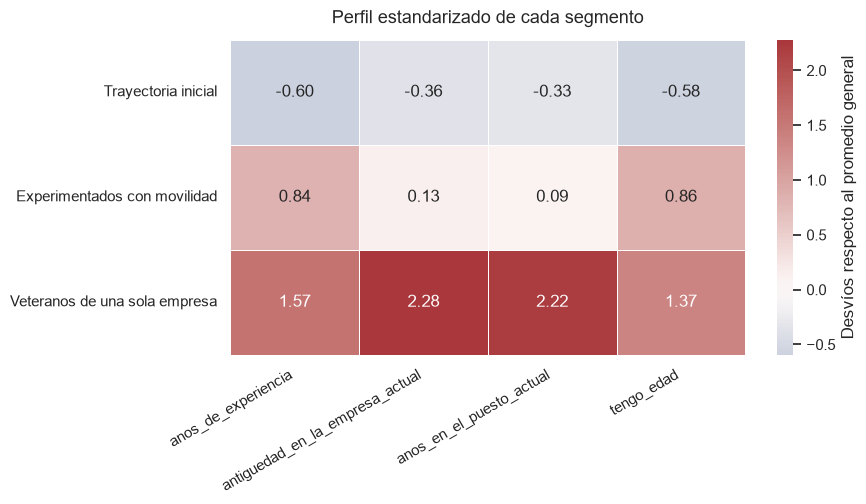

In [26]:
perfil = df_cl.groupby("segmento").agg(
    personas=("salario", "size"),
    experiencia=("anos_de_experiencia", "mean"),
    antiguedad_empresa=("antiguedad_en_la_empresa_actual", "mean"),
    anos_en_puesto=("anos_en_el_puesto_actual", "mean"),
    edad=("tengo_edad", "mean"),
    salario_mediana=("salario", "median"),
    salario_media=("salario", "mean"),
    pct_jerarquico=("es_jerarquico", "mean"),
    pct_dolarizado=("sueldo_dolarizado", "mean"),
)
perfil["% de personas"] = perfil["personas"] / perfil["personas"].sum() * 100
perfil["pct_jerarquico"] *= 100
perfil["pct_dolarizado"] *= 100
perfil = perfil.sort_values("experiencia")

print("Perfil de cada segmento (unidades originales):")
display(perfil.style.format({
    "personas": "{:,.0f}",
    "experiencia": "{:.1f}",
    "antiguedad_empresa": "{:.1f}",
    "anos_en_puesto": "{:.1f}",
    "edad": "{:.1f}",
    "salario_mediana": formato_moneda,
    "salario_media": formato_moneda,
    "pct_jerarquico": "{:.1f}%",
    "pct_dolarizado": "{:.1f}%",
    "% de personas": "{:.1f}%",
}))

# Perfil estandarizado: cuánto se aleja cada segmento del promedio general (en desvíos), solo de las variables usadas para agrupar
perfil_z = pd.DataFrame(X_final, columns=vars_final).groupby(df_cl["segmento"].values).mean().loc[perfil.index]

plt.figure(figsize=(9, 4 + 0.4 * len(perfil_z)))
sns.heatmap(perfil_z, annot=True, fmt=".2f", cmap="vlag", center=0, linewidths=0.5,
            cbar_kws={"label": "Desvíos respecto al promedio general"})
plt.title("Perfil estandarizado de cada segmento", fontsize=13, pad=12)
plt.xticks(rotation=30, ha="right")
plt.ylabel("")
plt.tight_layout()
plt.show()

**Cómo leer el mapa de calor:** un valor de +1 significa que el segmento está un desvío estándar por encima del promedio general en esa variable. Buscá en cada fila qué la distingue de las demás: esa es la base para ponerle nombre.

> **Conclusión** Los tres segmentos se ordenan por trayectoria y, sobre todo, por permanencia en la empresa. "Trayectoria inicial" (62,6%) tiene poca experiencia (5,2 años) y es el único por debajo del promedio en las cuatro variables. "Experimentados con movilidad" (29,2%) tiene mucha experiencia (16,8 años) pero poca permanencia (5,2 años en la empresa), o sea que acumuló carrera cambiando de empresa o de puesto. "Veteranos de una sola empresa" (8,2%) lleva 16,5 años en la misma empresa y 12,1 en el puesto, más de dos desvíos por encima del promedio.

### 10.3 Composición de cada segmento

Variables que **no** se usaron para agrupar: si los segmentos describen perfiles reales, deberían diferenciarse también en ellas.

In [27]:
# Seniority
tabla_sen = pd.crosstab(df_cl["segmento"], df_cl["seniority"], normalize="index").mul(100).round(1)
print("% de cada seniority dentro de cada segmento:")
display(tabla_sen[[c for c in orden_seniority if c in tabla_sen.columns]].loc[perfil.index])

ari_sen_final = adjusted_rand_score(df_cl["seniority"], df_cl["cluster"])
print(f"ARI entre segmentos finales y seniority: {ari_sen_final:.3f}")

# Tipo de contrato y modalidad
for col in ["tipo_de_contrato", "modalidad_de_trabajo"]:
    tabla = pd.crosstab(df_cl["segmento"], df_cl[col], normalize="index").mul(100).round(1)
    print(f"\n% de {col} dentro de cada segmento:")
    display(tabla.loc[perfil.index])

# Puestos más frecuentes
top_puestos = df_cl["trabajo_de"].value_counts().head(6).index
puesto_agrupado = df_cl["trabajo_de"].where(df_cl["trabajo_de"].isin(top_puestos), "Otros")
print("\n% de puestos principales dentro de cada segmento:")
display(pd.crosstab(df_cl["segmento"], puesto_agrupado, normalize="index").mul(100).round(1).loc[perfil.index])

# Género (variable no usada para agrupar)
print("\n% de género dentro de cada segmento:")
display(pd.crosstab(df_cl["segmento"], df_cl["genero"], normalize="index").mul(100).round(1).loc[perfil.index])

% de cada seniority dentro de cada segmento:


seniority,Junior,Semi-Senior,Senior
segmento,,,
Trayectoria inicial,15.8,47.4,36.9
Experimentados con movilidad,0.2,4.3,95.5
Veteranos de una sola empresa,0.0,1.4,98.6


ARI entre segmentos finales y seniority: 0.061

% de tipo_de_contrato dentro de cada segmento:


tipo_de_contrato,Contractor,Freelance,Participación Societaria En Una Cooperativa,Staff (Planta Permanente),Tercerizado (Trabajo A Través De Consultora O Agencia)
segmento,,,,,
Trayectoria inicial,16.6,1.9,0.5,71.1,9.8
Experimentados con movilidad,13.1,1.9,1.2,77.5,6.3
Veteranos de una sola empresa,6.1,3.1,0.8,86.6,3.4



% de modalidad_de_trabajo dentro de cada segmento:


modalidad_de_trabajo,100% Presencial,100% Remoto,Híbrido (Presencial Y Remoto)
segmento,,,
Trayectoria inicial,6.7,49.2,44.1
Experimentados con movilidad,8.4,45.6,46.0
Veteranos de una sola empresa,25.4,27.7,46.9



% de puestos principales dentro de cada segmento:


trabajo_de,Bi Analyst / Data Analyst,Developer,Manager / Director,Otros,Qa / Tester,Sysadmin / Devops / Sre,Technical Leader
segmento,,,,,,,
Trayectoria inicial,5.2,40.8,4.3,30.1,5.8,9.1,4.8
Experimentados con movilidad,1.5,24.0,16.0,29.3,3.4,14.6,11.2
Veteranos de una sola empresa,2.8,19.3,13.7,34.9,2.8,16.8,9.8



% de género dentro de cada segmento:


genero,Hombre Cis,Mujer Cis
segmento,,
Trayectoria inicial,76.0,24.0
Experimentados con movilidad,84.9,15.1
Veteranos de una sola empresa,87.2,12.8


> **Conclusión** Aunque estas variables no se usaron para agrupar, acompañan el patrón. A mayor trayectoria hay más roles de gestión y liderazgo (Manager/Director pasa de 4,3% a 16,0% y 13,7%) y menos desarrolladores (de 40,8% a 24,0% y 19,3%). Los veteranos trabajan más de forma presencial (25,4% contra 6,7% y 8,4%) y tienen más contratos de planta (86,6%). La proporción de mujeres baja de 24,0% en el grupo inicial a 15,1% y 12,8% en los de más trayectoria. Son descripciones, no explicaciones.

### 10.4 ¿Se diferencian los segmentos en salario?

Esta es la pregunta de negocio original. El salario **no se usó** para agrupar, así que cualquier diferencia entre segmentos surge solo de la trayectoria.

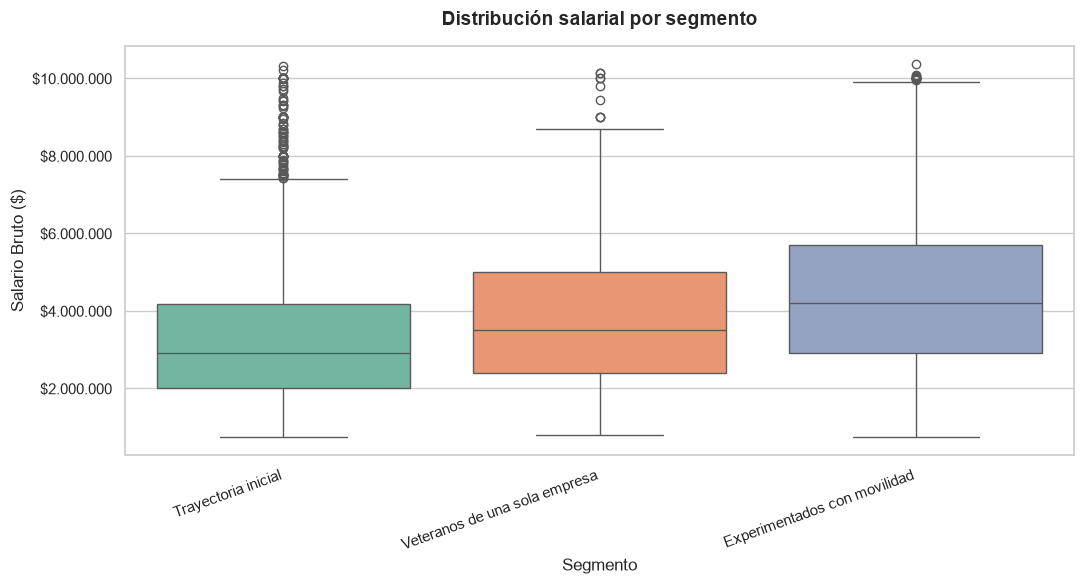

Segmento con menor mediana salarial: Trayectoria inicial ($2.900.000,00)
Segmento con mayor mediana salarial: Experimentados con movilidad ($4.199.998,00)
El segmento mejor pago tiene una mediana 1.45 veces la del segmento de menor mediana.


In [28]:
orden_salario = df_cl.groupby("segmento")["salario"].median().sort_values().index

plt.figure(figsize=(11, 6))
ax = sns.boxplot(data=df_cl, x="segmento", y="salario", order=orden_salario, palette="Set2")
plt.title("Distribución salarial por segmento", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Segmento", fontsize=12)
plt.ylabel("Salario Bruto ($)", fontsize=12)
plt.xticks(rotation=20, ha="right")
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"${x:,.0f}".replace(",", ".")))
plt.tight_layout()
plt.show()

medianas = df_cl.groupby("segmento")["salario"].median().sort_values()
print(f"Segmento con menor mediana salarial: {medianas.index[0]} ({formato_moneda(medianas.iloc[0])})")
print(f"Segmento con mayor mediana salarial: {medianas.index[-1]} ({formato_moneda(medianas.iloc[-1])})")
print(f"El segmento mejor pago tiene una mediana {medianas.iloc[-1] / medianas.iloc[0]:.2f} veces la del segmento de menor mediana.")

> **Conclusión** El salario sube con la trayectoria, pero no en línea recta. "Experimentados con movilidad" tiene la mediana más alta ($4,2 M), unas 1,45 veces la de "Trayectoria inicial" ($2,9 M). "Veteranos de una sola empresa" queda en el medio ($3,5 M) pese a ser quienes más experiencia tienen. Las cajas se pisan bastante, así que los segmentos indican tendencias y no reglas. Que un segmento cobre más no prueba que su trayectoria sea la causa: pueden influir el puesto, la modalidad o el tipo de empresa.

## Parte 11: Conclusiones, registro de decisiones y exportación

### 11.1 Resumen de lo decidido con los datos

In [29]:
print("=" * 70)
print("RESUMEN DEL MODELO FINAL")
print("=" * 70)
print(f"Algoritmo final       : {descripcion_modelo}")
print(f"Variables de entrada  : {vars_final}")
print(f"Transformación log1p  : {log_final if log_final else 'ninguna'}")
print(f"Segmentos             : {df_cl.loc[df_cl['cluster'] != -1, 'cluster'].nunique()}")
print(f"Silhouette            : {sil_final:.3f}")
if algoritmo_final == "K-Means":
    print(f"Estabilidad (ARI promedio entre 10 semillas): {ari_final.mean():.3f} (mínimo {ari_final.min():.3f})")
print(f"ARI vs seniority      : {ari_sen_final:.3f}")
print(f"Motivo de la elección : {motivo}")

RESUMEN DEL MODELO FINAL
Algoritmo final       : K-Means (k = 3, versión 'V1 Base')
Variables de entrada  : ['anos_de_experiencia', 'antiguedad_en_la_empresa_actual', 'anos_en_el_puesto_actual', 'tengo_edad']
Transformación log1p  : ninguna
Segmentos             : 3
Silhouette            : 0.392
Estabilidad (ARI promedio entre 10 semillas): 0.980 (mínimo 0.978)
ARI vs seniority      : 0.061
Motivo de la elección : es el modelo elegible con mayor Silhouette (0.392), sin empate técnico.


> **Conclusión** El resumen confirma el modelo final: K-Means con 3 segmentos, las 4 variables de trayectoria sin transformar, un Silhouette de 0,392 (separación moderada) y una estabilidad de 0,98 entre semillas. El ARI de 0,06 contra el seniority indica que los grupos aportan información distinta a la que ya trae esa columna.

### 11.2 Registro de decisiones

| # | Decisión | Criterio | Alternativa descartada o revisada | Dónde |
|---|---|---|---|---|
| 1 | Usar `dataset_clean.csv` | Necesitamos unidades originales para interpretar, y las distancias no funcionan bien con muchas columnas 0/1 | `dataset_features.csv` (pensado para predecir salario) | Parte 1 |
| 2 | Agrupar solo con variables numéricas de trayectoria | Lo que queremos segmentar es el recorrido profesional; lo demás se usa para interpretar y validar | Incluir `salario` (los clusters serían rangos de sueldo) o categóricas (distorsionan las distancias) | 2.1 |
| 3 | No eliminar valores extremos de trayectoria | Son perfiles reales; solo se descartan los imposibles (ya filtrados en el 01) | Recortar por IQR | 2.2 |
| 4 | Eliminar filas con faltantes en las variables para agrupar | Imputar con la mediana crea personas "promedio" artificiales | Imputación con mediana | 2.2 |
| 5 | Escalar con `StandardScaler` | Las distancias darían más peso a las variables con rangos más grandes | No escalar | Parte 3 |
| 6 | K-Means como modelo principal; DBSCAN y jerárquico como competidores | Segmentar a toda la muestra en pocos perfiles interpretables | Elegir el algoritmo sin compararlo | Parte 4 |
| 7 | Elegir k entre 3 y 6, con clusters de al menos 5% y mayor Silhouette | Segmentos accionables; el codo no suele ser claro en datos reales | Elegir solo por codo o por Silhouette puro | 5.1 |
| 8 | Evaluar estabilidad con 10 semillas y ARI | Un modelo que cambia con la semilla no sirve para segmentar | Confiar en una única corrida | 5.4 |
| 9 | Validar contra `seniority` | Variable no usada que debería relacionarse con la trayectoria | Validar solo con gráficos | 5.5 |
| 10 | Comparar 3 versiones de los datos y elegir por Silhouette, con empate técnico de 0,02 y preferencia por la más simple | Parsimonia (mismo principio que `max_depth` en el notebook 04) | Quedarse con la versión base sin revisarla | 5.6 |
| 11 | DBSCAN: `eps` guiado por el gráfico de distancias y aceptación con un criterio explícito (2 a 6 clusters, ruido de a lo sumo 10%, cluster mínimo de 5%) | Que el Silhouette sin ruido no favorezca a DBSCAN de forma injusta | Comparar solo el Silhouette | Parte 6 |
| 12 | Jerárquico con enlace Ward y corte elegido con la misma regla que K-Means | Comparación justa; Ward es el único enlace con grupos de tamaño útil | Single, complete y average (grupo gigante y grupos de una persona) | Parte 7 |
| 13 | Elegir el modelo final entre los elegibles por Silhouette, con empate técnico de 0,02 y preferencia por K-Means | Regla definida antes de ver los resultados; K-Means es el más fácil de explicar y de aplicar a personas nuevas | Elegir por preferencia personal | Parte 8 |
| 14 | Usar PCA y SVD para visualizar y verificar, no para agrupar | Los clusters se calculan con todas las variables; reducir no mejoró el resultado | Agrupar sobre los componentes | Parte 9 |

### 11.3 Limitaciones

* **Los segmentos son descriptivos, no causales.** Que un segmento cobre más no significa que su trayectoria sea la causa.
* **Solo usamos variables numéricas.** Rol, tecnologías, provincia o tipo de contrato quedan afuera del agrupamiento. Se usan para describir, pero no para formar los grupos, porque estos algoritmos trabajan con distancias numéricas.
* **El Silhouette se interpreta con cuidado.** Un valor bajo o moderado indica límites difusos entre segmentos, que es lo esperable si la trayectoria profesional es un continuo. Además, el Silhouette de modelos con distinta cantidad de grupos o de variables no es estrictamente comparable.
* **Las variables son discretas y están en años enteros.** Hay muchos valores repetidos, lo que afecta sobre todo a DBSCAN.
* **La grilla de DBSCAN es acotada.** Se probaron 8 valores de `eps` y 4 de `min_samples`; una grilla más fina podría cambiar el resultado, aunque la tendencia (un bloque dominante) es clara.
* **Los datos son autorreportados.** Las preguntas de experiencia, antigüedad y años en el puesto se responden por separado, y pueden aparecer combinaciones poco coherentes (ver 2.2).

### 11.4 Exportación

Guardamos el dataset con el segmento asignado para poder usarlo en análisis posteriores.

In [30]:
# Exportar el DataFrame con los segmentos
df_cl.to_csv('../data/dataset_clusters.csv', index=False)

print("¡Archivo exportado exitosamente en 'data/dataset_clusters.csv'!")
print(f"Filas: {df_cl.shape[0]} | Columnas: {df_cl.shape[1]} (incluye 'cluster' y 'segmento')")

¡Archivo exportado exitosamente en 'data/dataset_clusters.csv'!
Filas: 4387 | Columnas: 29 (incluye 'cluster' y 'segmento')


## Conclusión general

En lenguaje simple, esto es lo que se hizo y lo que se encontró:

* **Qué se buscó:** ver si las personas de la encuesta forman grupos naturales según su recorrido profesional (años de experiencia, antigüedad en la empresa, años en el puesto y edad), sin mirar el sueldo.
* **Qué se encontró:** tres perfiles. Una **trayectoria inicial** (62,6% de las personas, unos 5 años de experiencia), **experimentados con movilidad** (29,2%, unos 17 años de experiencia pero poco tiempo en cada empresa) y **veteranos de una sola empresa** (8,2%, 16 años en la misma empresa).
* **Cómo se eligió el modelo:** se compararon tres algoritmos con reglas fijadas de antemano. K-Means ganó: es estable (casi los mismos grupos con distintas semillas) y obtuvo la mejor separación entre los modelos válidos. El jerárquico (Ward) llegó a una estructura parecida, lo que refuerza el resultado. DBSCAN no logró segmentar, pero sirvió para detectar a 147 personas con trayectorias muy largas.
* **Qué tan nítidos son los grupos:** moderadamente. La trayectoria profesional es un continuo, no hay saltos claros entre un perfil y otro, y por eso hay personas de frontera, sobre todo en los grupos más chicos.
* **Qué dicen del salario:** aunque no se usó para armarlos, los grupos se diferencian: los experimentados con movilidad tienen la mediana más alta ($4,2 M) y la trayectoria inicial la más baja ($2,9 M). Es una descripción, no una explicación: otros factores como el puesto o la modalidad también influyen.